# DTE (Deutsche Telekom): the underlying, the vol curves and a vol thesis
Long 100 Nov-26 ATM straddles, RED book, 12–14 Oct 2026. Run all cells; the last one writes `dte_report.html`.

| `data/` file | Content |
|---|---|
| `spot_1min_full.csv` | RED model mid every minute, 12–14 Oct (pre-open to closing auction) |
| `trades.csv` | every DTE option trade on Eurex, with the Xetra stock bid/ask at that moment |
| `straddle_1min.csv` | Nov-26 K=25: spot, forward, tte, rate, implied vol, every minute |
| `straddle_quotes_1min.csv` | Nov-26 K=25 call and put: bid, ask, desk theo, desk delta, every minute |
| `fwd30_theo.csv` | 30-day forward backed out of option trades, every 30 minutes |
| `daily_ohlc.csv` | daily open/high/low/close, 9–14 Oct |
| `daily_closes.csv` | daily closes, Aug 2025 – Oct 2026 |
| `forward_curve.csv` | forward, rate and tte for every expiry, 14 Oct close |
| `forward_curve_daily.csv` | forward and ATM vol for every expiry at each close, 12–14 Oct |
| `dividends.csv` | stored dividends (`eurex_params.dividends`) |
| `atm_term_structure.csv` | latest ATM vol per expiry |
| `atm_history.csv` | ATM vol per expiry at each close, 8–14 Oct |
| `strike_vols_history.csv` | every listed strike's vol per expiry at each close, 8–14 Oct |
| `events.csv` | DTE and T-Mobile US results dates, with sources |
| `mako_events.csv` | events priced by Mako for DTE (the desk's event table) |
| `test_15oct_1min.csv` | Nov-26 K=25 every minute on 15 Oct (the out-of-sample day for the theta test) |

In [1]:
import re, base64, io, html
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from scipy.stats import norm
from scipy.optimize import brentq
from pandas.tseries.offsets import BDay
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
import warnings; warnings.filterwarnings("ignore", message="obj.round has no effect")

DATA, TZ = "data/", "Europe/Berlin"
N = 100 * 100            # 100 straddles x 100 shares (Eurex contract size)
CONTRACT_SIZE = 100
SKIP_OPEN_MIN = 5        # first minutes of each session dropped (stale print at the 14 Oct open)
DAYS = 252
figs = {}

def load(name, tcol="ts"):
    df = pd.read_csv(DATA + name)
    df.index = pd.DatetimeIndex(pd.to_datetime(df[tcol].str.replace(" UTC", ""), utc=True)).tz_convert(TZ)
    return df.drop(columns=[tcol]).sort_index()

def session(df, start=f"09:{SKIP_OPEN_MIN:02d}", end="17:30"):
    t = df.index.strftime("%H:%M")
    return df[(t >= start) & (t <= end)]

def expiry_date(term):
    # Eurex expiry from the term name: monthlies = 3rd Friday, "W<n>" weeklies = n-th Friday
    mon, yr, wk = re.match(r"([A-Za-z]{3})-(\d{4})(?: W(\d))?", term).groups()
    first = pd.Timestamp(f"1 {mon} {yr}")
    fridays = pd.date_range(first, first + pd.offsets.MonthEnd(0), freq="W-FRI")
    return fridays[int(wk) - 1] if wk else fridays[2]

def black76(F, K, T, vol, r):
    T = np.maximum(T, 1e-8); s = vol * np.sqrt(T)
    d1 = (np.log(F / K) + 0.5 * s**2) / s; d2 = d1 - s; df = np.exp(-r * T)
    price = df * (F * (2 * norm.cdf(d1) - 1) - K * (2 * norm.cdf(d2) - 1))
    return dict(price=price, delta=df * (2 * norm.cdf(d1) - 1), gamma=2 * df * norm.pdf(d1) / (F * s),
                vega=2 * df * F * norm.pdf(d1) * np.sqrt(T))

In [2]:
spot_full = load("spot_1min_full.csv", "time_bucket_1m")
spot = session(spot_full)["avg_spot_price"].rename("spot")

tr = load("trades.csv", "exchange_timestamp")            # each trade recorded twice; OST_Q has the raw Xetra quote
tr = tr[(tr.algo == "OST_Q") & (tr.index.strftime("%Y-%m-%d") == tr.trade_date)].copy()
tr["stock_mid"] = (tr.raw_bv_bid + tr.raw_bv_ask) / 2
tr["stock_spread"] = tr.raw_bv_ask - tr.raw_bv_bid
HALF_SPREAD = tr.stock_spread.mean() / 2                 # cost per share of each stock hedge trade

st = session(load("straddle_1min.csv")); st["ivol"] /= 100
f30 = session(load("fwd30_theo.csv", "time_bucket_30m"), "09:00", "17:00")["fwd_underlying_30d_term"]
fc = pd.read_csv(DATA + "forward_curve.csv").sort_values("tte").reset_index(drop=True)
fcd = pd.read_csv(DATA + "forward_curve_daily.csv")
ohlc = pd.read_csv(DATA + "daily_ohlc.csv").set_index("trade_date")
atm = pd.read_csv(DATA + "atm_term_structure.csv").sort_values("tte").set_index("term")
atm_hist = pd.read_csv(DATA + "atm_history.csv")
sv_hist = pd.read_csv(DATA + "strike_vols_history.csv")
dc = pd.read_csv(DATA + "daily_closes.csv", parse_dates=["trade_date"]).set_index("trade_date").close_px.sort_index()
dv = pd.read_csv(DATA + "dividends.csv")
ev = pd.read_csv(DATA + "events.csv", parse_dates=["event_date"]).sort_values("event_date")
mk = pd.read_csv(DATA + "mako_events.csv")
test = session(load("test_15oct_1min.csv")); test["ivol"] /= 100      # 15 Oct, same session filter

q = session(load("straddle_quotes_1min.csv"))            # call + put quotes, two-sided only
q.loc[(q.bid <= 0) | (q.ask <= q.bid), ["bid", "ask"]] = np.nan
c, p = q[q.opt_type == "C"], q[q.opt_type == "P"]
sq = pd.DataFrame({"theo": c.theo + p.theo, "delta": c.delta + p.delta, "bid": c.bid + p.bid, "ask": c.ask + p.ask})
sq["mid"], sq["spread"] = (sq.bid + sq.ask) / 2, sq.ask - sq.bid
sq = sq.reindex(st.index).ffill()

TTE_PER_DAY = (-st.tte.groupby(st.index.date).first().diff()).mean()     # RED's clock per weekday
AS_OF = spot.index.max().tz_localize(None).normalize() + BDay(1)
print(f"RED clock {TTE_PER_DAY:.5f} per weekday (1/{1/TTE_PER_DAY:.0f} year); hedge cost €{HALF_SPREAD:.4f}/share; as of {AS_OF:%d %b %Y}")

RED clock 0.00385 per weekday (1/260 year); hedge cost €0.0064/share; as of 15 Oct 2026


## 1. Forward curve, dividends, borrow, rolls
Carry = ln(F/S)/tte; implied dividend + borrow = r − carry; cash dividend between expiries = F₁·e^{r_fwd·Δt} − F₂ (r_fwd = forward rate between them); rolls = forward differences.
Then the stored dividends: forwards rebuilt from spot, rates and dividends, with borrow solved as the only unknown.

       term    tte     fwd  interest_rate   carry  implied_div_plus_borrow  roll_points  implied_cash_div
   Oct-2026 0.0077 25.3157         0.0284  0.0293                  -0.0009          NaN               NaN
Oct-2026 W4 0.0273 25.3297         0.0284  0.0285                  -0.0001       0.0140            0.0002
Oct-2026 W5 0.0470 25.3436         0.0285  0.0282                   0.0002       0.0139            0.0003
Nov-2026 W1 0.0666 25.3575         0.0285  0.0282                   0.0004       0.0139            0.0003
Nov-2026 W2 0.0858 25.3715         0.0286  0.0283                   0.0003       0.0140            0.0000
   Nov-2026 0.1054 25.3851         0.0285  0.0281                   0.0004       0.0137            0.0003
   Dec-2026 0.1804 25.4361         0.0283  0.0276                   0.0007       0.0510            0.0024
   Mar-2027 0.4201 25.6247         0.0295  0.0294                   0.0001       0.1886           -0.0022
   Jun-2027 0.6678 24.8759         0.0308 -0.0


Live stored dividends:
        region  year    ex_date  value             updated
BOF_BLOOMBERG  2026 2026-04-02   1.00 2026-04-29 18:09:03
          RED  2026 2026-04-02   1.00 2026-04-01 14:13:10
          RED  2027 2027-04-15   0.95 2026-04-20 06:45:23
          RED  2028 2028-04-11   0.77 2024-05-09 14:55:23
  VTSTOCKS_DE  2026 2026-04-02   1.00 2026-02-26 08:54:28
  VTSTOCKS_DE  2027 2027-04-15   1.05 2026-09-15 09:16:16
  VTSTOCKS_DE  2028 2028-04-13   1.00 2026-09-15 09:15:49
  VTSTOCKS_DE  2029 2029-04-13   1.00 2026-09-15 09:15:57

Implied vs stored:
       implied 14 Oct  RED stored  implied 12 Oct  VTSTOCKS_DE stored
2027           0.959        0.95           1.054                1.05
2028           0.783        0.77           1.020                1.00
2029           0.020        0.00           0.976                1.00

                    max |RED fwd − rebuilt| (EUR)
10-12 RED                                  0.367
10-12 VTSTOCKS_DE                          0.030
10-13 R

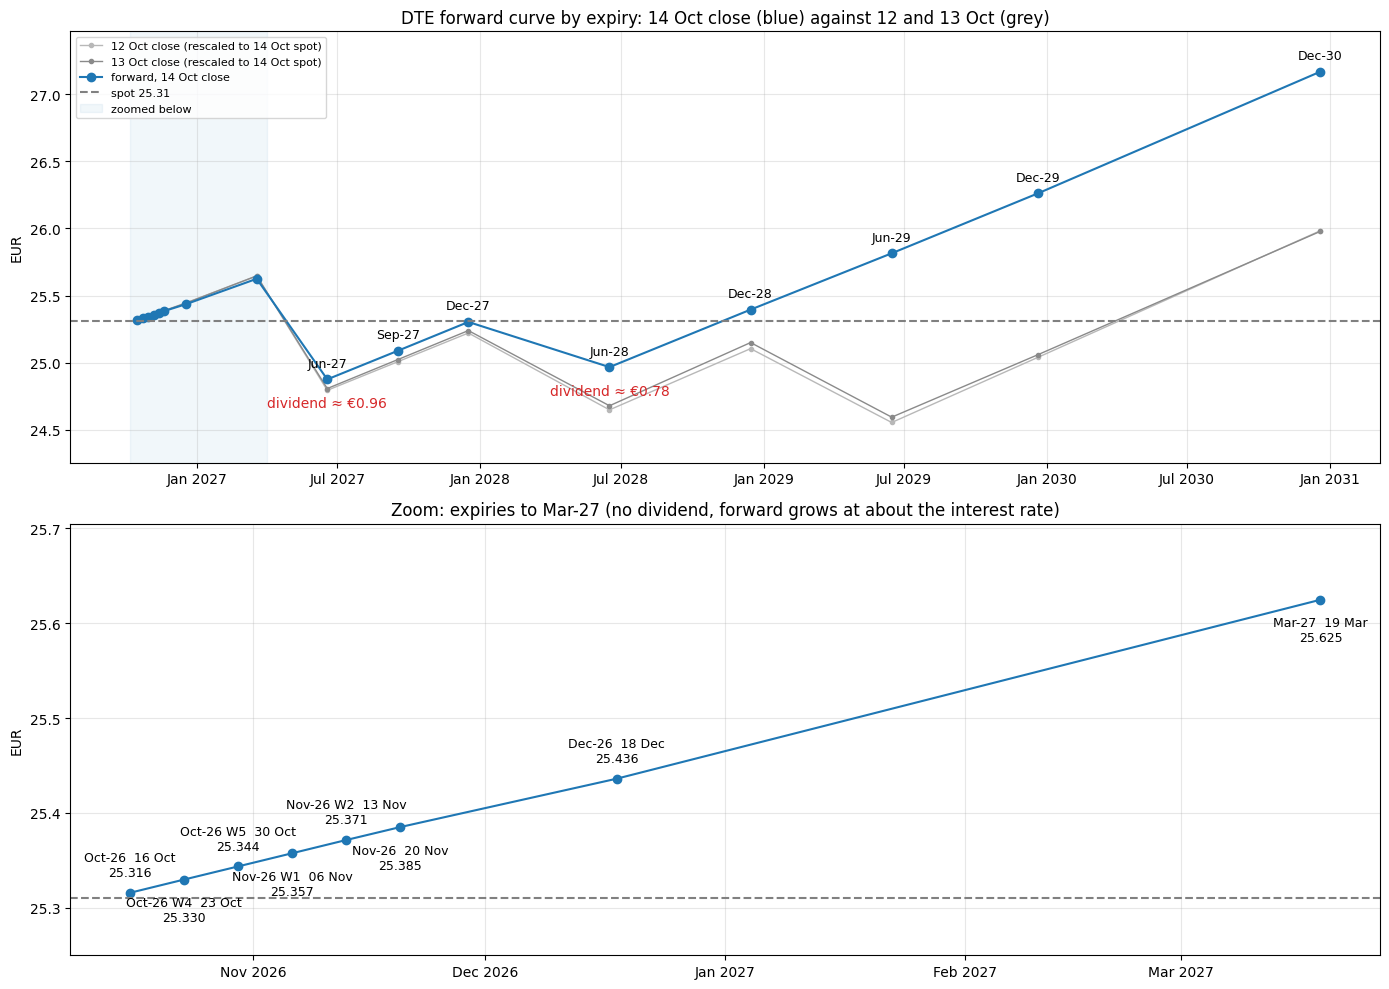

In [3]:
fc["carry"] = np.log(fc.fwd / fc.under) / fc.tte
fc["implied_div_plus_borrow"] = fc.interest_rate - fc.carry
dT = fc.tte.diff(); rt = fc.interest_rate * fc.tte
fc["roll_points"] = fc.fwd.diff()
fc["implied_cash_div"] = fc.fwd.shift() * np.exp((rt - rt.shift()) / dT * dT) - fc.fwd
fc["expiry"] = fc.term.map(expiry_date)
curve = fc[["term", "tte", "fwd", "interest_rate", "carry", "implied_div_plus_borrow", "roll_points", "implied_cash_div"]]
divs = fc.loc[fc.implied_cash_div > 0.10, ["term", "implied_cash_div"]]
carry_st = np.log(st.fwd / st.spot) / st.tte
nov_div_borrow = (st.interest_rate - carry_st).mean()
print(curve.round(4).to_string(index=False))
print(f"\nNov-26 over the window: r {st.interest_rate.mean():.3%}, carry {carry_st.mean():.3%}, div+borrow {nov_div_borrow:.3%}")

# the curve at each close
fcd["expiry"] = pd.to_datetime(fcd.expiry_timestamp.str.replace(" UTC", "")).dt.normalize()
assert all(fcd.term.map(expiry_date) == fcd.expiry)
fcd = fcd.merge(fc[["term", "interest_rate"]], on="term")
divs_daily = {}
for d_, g in fcd.groupby("trade_date"):
    g = g.sort_values("tte"); dT_ = g.tte.diff(); rt_ = g.interest_rate * g.tte
    divs_daily[d_] = (g.fwd.shift() * np.exp((rt_ - rt_.shift()) / dT_ * dT_) - g.fwd).set_axis(g.term)
divs_daily = pd.DataFrame(divs_daily).reindex(fcd.drop_duplicates("term").sort_values("tte").term)

# stored dividends: latest entry per book and year is the live one
dv["ex_date"] = pd.to_datetime(dv.ex_date.str.split("@").str[0], format="%d-%b-%Y")
dv["updated"] = pd.to_datetime(dv.update_timestamp.str.replace(" UTC", ""))
dv["year"] = dv.ex_date.dt.year
live_divs = dv.sort_values("updated").groupby(["region", "year"]).tail(1).sort_values(["region", "ex_date"])[["region", "year", "ex_date", "value", "updated"]]

def rebuild(cday, region):
    g = cday.sort_values("tte"); d_ = live_divs[live_divs.region == region]; out = []
    for _, row in g.iterrows():
        hit = d_[(d_.ex_date > AS_OF - pd.Timedelta(days=7)) & (d_.ex_date <= row.expiry)]
        t_div = np.interp(hit.ex_date.map(pd.Timestamp.toordinal), g.expiry.map(pd.Timestamp.toordinal), g.tte)
        dl = list(zip(hit.value, t_div))
        f = lambda b: row.spot * np.exp((row.interest_rate - b) * row.tte) - sum(D * np.exp((row.interest_rate - b) * (row.tte - t)) for D, t in dl) - row.fwd
        out.append({"term": row.term, "diff_eur": f(0.0), "implied_borrow": brentq(f, -0.5, 0.5)})
    return pd.DataFrame(out).set_index("term")

days_fc = sorted(fcd.trade_date.unique()); last_day = days_fc[-1]
checks = {(d_, reg): rebuild(fcd[fcd.trade_date == d_], reg) for d_ in days_fc for reg in ["RED", "VTSTOCKS_DE"]}
summ = pd.DataFrame({f"{d_[5:]} {reg}": chk.loc[:"Dec-2028", "diff_eur"].abs().max() for (d_, reg), chk in checks.items()},
                    index=["max |RED fwd − rebuilt| (EUR)"]).T
nov_b = checks[(last_day, "RED")].loc["Nov-2026", "implied_borrow"]
stored = lambda reg, y: live_divs[(live_divs.region == reg) & (live_divs.year == y)].value.sum()
divs_compare = pd.DataFrame({
    "implied 14 Oct": divs_daily[last_day].reindex(["Jun-2027", "Jun-2028", "Jun-2029"]).values,
    "RED stored": [stored("RED", y) for y in (2027, 2028, 2029)],
    "implied 12 Oct": divs_daily[days_fc[0]].reindex(["Jun-2027", "Jun-2028", "Jun-2029"]).values,
    "VTSTOCKS_DE stored": [stored("VTSTOCKS_DE", y) for y in (2027, 2028, 2029)]}, index=["2027", "2028", "2029"])
print("\nLive stored dividends:\n", live_divs.to_string(index=False))
print("\nImplied vs stored:\n", divs_compare.round(3)); print("\n", summ.round(3)); print(f"\nBorrow at Nov-26: {nov_b:.3%}")

spot_now = fc.under.iloc[0]; short = lambda t: t.replace("-20", "-"); zoom_end = pd.Timestamp("2027-04-01")
fig, (ax, az) = plt.subplots(2, 1, figsize=(14, 10))
for d_, c_ in zip(days_fc[:-1], ["#b8b8b8", "#8a8a8a"]):
    g = fcd[fcd.trade_date == d_].sort_values("expiry")
    ax.plot(g.expiry, g.fwd / g.spot * spot_now, ".-", c=c_, lw=1, label=f"{d_[8:]} Oct close (rescaled to 14 Oct spot)")
ax.plot(fc.expiry, fc.fwd, "o-", label="forward, 14 Oct close"); ax.axhline(spot_now, ls="--", c="grey", label=f"spot {spot_now:.2f}")
ax.axvspan(fc.expiry.min() - pd.Timedelta(days=10), zoom_end, color="C0", alpha=.06, label="zoomed below")
for _, r in fc[fc.expiry > zoom_end].iterrows():
    ax.annotate(short(r.term), (r.expiry, r.fwd), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
for _, r in divs.iterrows():
    row = fc[fc.term == r.term].iloc[0]
    ax.annotate(f"dividend ≈ €{r.implied_cash_div:.2f}", (row.expiry, row.fwd), textcoords="offset points", xytext=(0, -20), ha="center", fontsize=10, color="C3")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylim(min(fc.fwd.min(), (fcd.fwd / fcd.spot * spot_now).min()) - 0.3, fc.fwd.max() + 0.3)
ax.set_ylabel("EUR"); ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=.3)
ax.set_title("DTE forward curve by expiry: 14 Oct close (blue) against 12 and 13 Oct (grey)")
z = fc[fc.expiry <= zoom_end].reset_index(drop=True)
az.plot(z.expiry, z.fwd, "o-"); az.axhline(spot_now, ls="--", c="grey")
for i, r in z.iterrows():
    az.annotate(f"{short(r.term)}  {r.expiry:%d %b}\n{r.fwd:.3f}", (r.expiry, r.fwd), textcoords="offset points",
                xytext=(0, 12 if i % 2 == 0 else -30), ha="center", fontsize=9)
az.xaxis.set_major_locator(mdates.MonthLocator()); az.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
az.set_ylim(spot_now - 0.06, z.fwd.max() + 0.08); az.set_ylabel("EUR"); az.grid(alpha=.3)
az.set_title("Zoom: expiries to Mar-27 (no dividend, forward grows at about the interest rate)")
fig.tight_layout(); figs["curve"] = fig; plt.show()

## 2. The move, 12–14 Oct
RED's model mid, checked against the Xetra quote at every option trade and the forward from option trades.

            open_px  high_px  low_px  close_px
trade_date                                    
2026-10-09   25.190   25.205  24.645     24.67
2026-10-12   24.990   24.990  24.525     24.87
2026-10-13   25.215   25.535  25.133     25.17
2026-10-14   25.218   25.320  24.950     25.32

 option trades compared    1447.0000
mean diff (EUR)              0.0003
median abs diff (EUR)        0.0050
95% abs diff (EUR)           0.0200

             prev close  08:59 pre-open   09:00    09:01    09:05 first option trade (Berlin)  Xetra mid then
2026-10-12       24.67           24.74  24.775  24.8900  24.9900                    09:03:20          24.925
2026-10-13       24.87           24.99  25.230  25.1883  25.2150                    09:00:15          25.150
2026-10-14       25.17           25.24  24.560  24.5600  25.2176                    09:03:13          25.165

             option_trades  contracts  one_tick_spread
trade_date                                           
2026-10-12            57

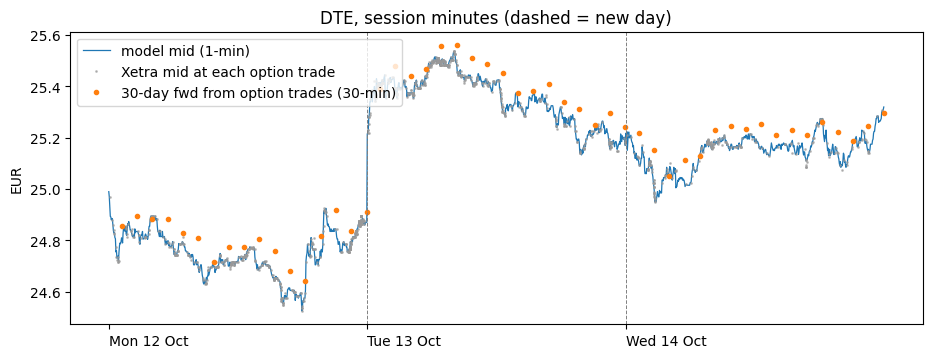

In [4]:
print(ohlc.round(3))
move_total = np.log(ohlc.close_px.iloc[-1] / ohlc.close_px.iloc[0])
chk = tr.assign(m=tr.index.floor("min")).join(spot_full.avg_spot_price.rename("model"), on="m").dropna(subset=["model"])
xd = chk.stock_mid - chk.model
xetra_check = pd.Series({"option trades compared": len(chk), "mean diff (EUR)": xd.mean(),
                         "median abs diff (EUR)": xd.abs().median(), "95% abs diff (EUR)": xd.abs().quantile(.95)})
def at(day, hhmm):
    v = spot_full.avg_spot_price[spot_full.index.strftime("%Y-%m-%d %H:%M") == f"{day} {hhmm}"]
    return v.iloc[0] if len(v) else np.nan
opens = pd.DataFrame({d_: {"prev close": ohlc.close_px.shift().get(d_), "08:59 pre-open": at(d_, "08:59"), "09:00": at(d_, "09:00"),
                           "09:01": at(d_, "09:01"), "09:05": at(d_, "09:05")} for d_ in ohlc.index[1:]}).T
ft = tr.assign(t=tr.index).groupby("trade_date").first()
opens["first option trade (Berlin)"] = ft.t.reindex(opens.index).dt.strftime("%H:%M:%S")
opens["Xetra mid then"] = ft.stock_mid.reindex(opens.index)
trades_daily = tr.groupby("trade_date").agg(option_trades=("trade_size", "size"), contracts=("trade_size", "sum"),
                                            one_tick_spread=("stock_spread", lambda v: (v.round(3) == 0.01).mean()))
print("\n", xetra_check.round(4).to_string()); print("\n", opens); print("\n", trades_daily)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(np.arange(len(spot)), spot.values, lw=.9, label="model mid (1-min)")
tq = session(tr)
ax.plot(np.clip(np.searchsorted(spot.index, tq.index.floor("min")), 0, len(spot) - 1), tq.stock_mid.values, ".", ms=2, c="#999", alpha=.6, label="Xetra mid at each option trade")
ax.plot(np.clip(np.searchsorted(spot.index, f30.index + pd.Timedelta(minutes=30)), 0, len(spot) - 1), f30.values, "o", ms=3, label="30-day fwd from option trades (30-min)")
newday = np.flatnonzero(np.r_[False, spot.index.date[1:] != spot.index.date[:-1]])
for i in newday: ax.axvline(i, ls="--", c="grey", lw=.7)
ax.set_xticks(np.r_[0, newday]); ax.set_xticklabels(sorted(set(spot.index.strftime("%a %d Oct"))), ha="left")
ax.set_ylabel("EUR"); ax.legend(loc="upper left"); ax.set_title("DTE, session minutes (dashed = new day)")
figs["move"] = fig; plt.show()

## 3. Realised vol
Xetra trades 09:00–17:30 CET: 8.5 hours, so the day is not inside 8 hours.

**Standard:** σ = √( mean(r²) × bars per day × 252 ), r = log return between bars within a session (510 one-minute or 17 thirty-minute bars a day).
**RED's clock:** σ = √( Σr² ÷ Σ∆tte ), where ∆tte is the time RED's clock burned over the same bars. Implied vol is quoted per unit of that clock, so this is the like-for-like comparison.
**Implied:** RED's implied vol for the Nov-26 25-strike (`ivol` in `straddle_1min.csv`), averaged over each day's minutes.

             1min   5min  10min  30min  30min option fwd  1min RED clock  30min RED clock  implied (avg)
2026-10-12  0.208  0.238  0.249  0.166             0.188           0.262            0.213          0.314
2026-10-13  0.195  0.187  0.156  0.144             0.134           0.246            0.193          0.291
2026-10-14  0.191  0.182  0.198  0.217             0.137           0.241            0.254          0.289
ALL         0.198  0.204  0.205  0.178             0.155           0.250            0.222          0.298

RED-clock ingredients (30-min):
             bars    sum r²  tte burned  tte as trading days  vol = √(Σr²/tte)  same r², ÷252 clock
2026-10-12  15.0  0.000093    0.002065             0.536945          0.212752             0.163385
2026-10-13  15.0  0.000077    0.002065             0.536956          0.193476             0.148584
2026-10-14  15.0  0.000133    0.002065             0.537026          0.254172             0.195209
ALL         45.0  0.000304    0.006195       

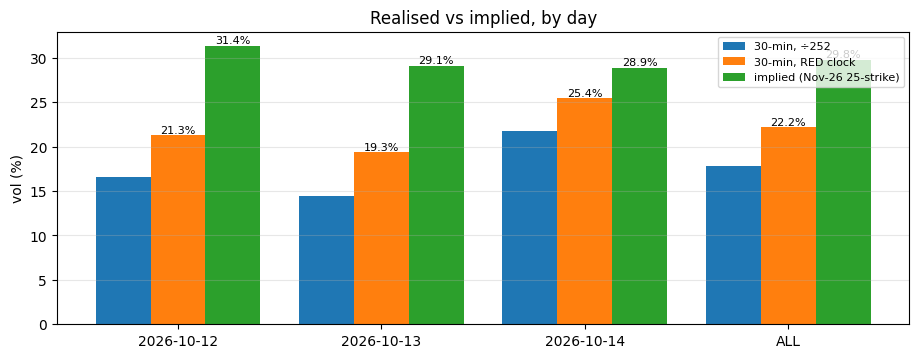

In [5]:
def rv_table(s, minutes):
    rets = [np.log(g.resample(f"{minutes}min", closed="right", label="right").last().dropna()).diff().dropna() for _, g in s.groupby(s.index.date)]
    r = pd.concat(rets); ann = (510 / minutes) * DAYS
    out = r.groupby(r.index.date).apply(lambda x: np.sqrt((x**2).mean() * ann)); out.index = out.index.astype(str)
    out["ALL"] = np.sqrt((r**2).mean() * ann); return out

rv = pd.DataFrame({f"{m}min": rv_table(spot, m) for m in (1, 5, 10, 30)})
r30 = np.log(f30).groupby(f30.index.date).diff().dropna()
x = r30.groupby(r30.index.date).apply(lambda v: np.sqrt((v**2).mean() * 17 * DAYS)); x.index = x.index.astype(str)
x["ALL"] = np.sqrt((r30**2).mean() * 17 * DAYS); rv["30min option fwd"] = x
st["r"] = np.log(st.spot).groupby(st.index.date).diff()
st["dtte"] = -st.tte.groupby(st.index.date).diff()
y = st.groupby(st.index.date).apply(lambda g: np.sqrt((g.r**2).sum() / g.dtte.sum())); y.index = y.index.astype(str)
y["ALL"] = np.sqrt((st.r**2).sum() / st.dtte.sum()); rv["1min RED clock"] = y
s30 = st[st.index.minute % 30 == 0]
r30s = np.log(s30.spot).groupby(s30.index.date).diff(); t30s = -s30.tte.groupby(s30.index.date).diff()
red_parts = pd.DataFrame({"bars": r30s.groupby(r30s.index.date).count(), "sum r²": (r30s**2).groupby(r30s.index.date).sum(),
                          "tte burned": t30s.groupby(t30s.index.date).sum()})
red_parts.index = red_parts.index.astype(str); red_parts.loc["ALL"] = red_parts.sum()
red_parts["tte as trading days"] = red_parts["tte burned"] / TTE_PER_DAY
red_parts["vol = √(Σr²/tte)"] = np.sqrt(red_parts["sum r²"] / red_parts["tte burned"])
red_parts["same r², ÷252 clock"] = np.sqrt(red_parts["sum r²"] / (red_parts["bars"] / 17 / DAYS))
rv["30min RED clock"] = red_parts["vol = √(Σr²/tte)"]
rv["implied (avg)"] = list(st.ivol.groupby(st.index.date).mean()) + [st.ivol.mean()]
cc = np.log(ohlc.close_px).diff().dropna()
on = np.log(ohlc.open_px / ohlc.close_px.shift()).dropna()
cc_vol = np.sqrt((cc**2).mean() * DAYS)
session_tte_share = (st.dtte.groupby(st.index.date).sum().mean()) / TTE_PER_DAY
print(rv.round(3)); print("\nRED-clock ingredients (30-min):\n", red_parts.round(6)); print(f"\nsession share of a RED day: {session_tte_share:.1%}")

fig, ax = plt.subplots(figsize=(11, 3.8)); xd = np.arange(len(rv)); w = .27
ax.bar(xd - w, rv["30min"] * 100, w, label="30-min, ÷252"); ax.bar(xd, rv["30min RED clock"] * 100, w, label="30-min, RED clock")
ax.bar(xd + w, rv["implied (avg)"] * 100, w, label="implied (Nov-26 25-strike)")
for i, v in enumerate(rv["implied (avg)"]): ax.annotate(f"{v:.1%}", (i + w, v * 100), ha="center", va="bottom", fontsize=8)
for i, v in enumerate(rv["30min RED clock"]): ax.annotate(f"{v:.1%}", (i, v * 100), ha="center", va="bottom", fontsize=8)
ax.set_xticks(xd); ax.set_xticklabels(rv.index); ax.set_ylabel("vol (%)"); ax.grid(alpha=.3, axis="y"); ax.legend(fontsize=8)
ax.set_title("Realised vs implied, by day"); figs["rv"] = fig; plt.show()

## 4. Greeks of 100 ATM straddles, desk check, market spread
Black-76 on the forward (the vol tables store greeks as 0). Per straddle and for the position (100 straddles × 100 shares), call and put legs separately.
Theta = price change over one RED day of tte; cash gamma = PnL from a 1% move after re-hedging (½·Γ·(1%·S)²); breakeven move = the daily move whose gamma PnL pays one day's theta.

                                     12 Oct 2026 09:05  15 Oct 2026 (latest snapshot)
strike                                         25.0000                        26.0000
forward                                        25.0680                        26.0853
spot                                           24.9900                        26.0098
time to expiry (RED years)                      0.1156                         0.1030
time to expiry (trading days)                  30.0545                        26.7854
implied vol                                     0.3241                         0.2855
call price                                      1.1303                         0.9920
put price                                       1.0626                         0.9070
straddle price                                  2.1929                         1.8989
straddle price, % of spot                       0.0878                         0.0730
call delta                                      0.5317

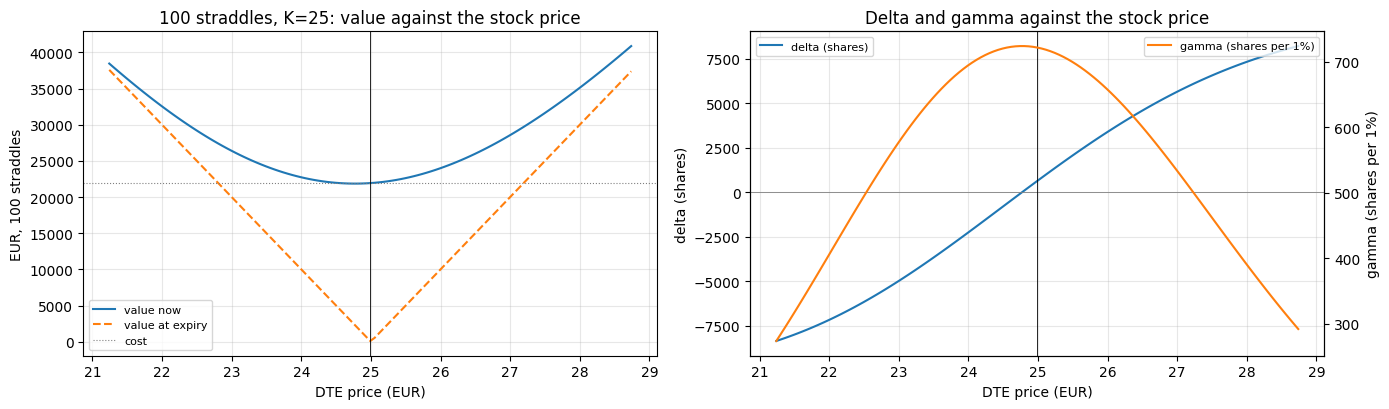

In [6]:
def leg_greeks(F, K, T, vol, r, call):
    T = max(T, 1e-8); s = vol * np.sqrt(T); d1 = (np.log(F / K) + 0.5 * s**2) / s; d2 = d1 - s; df = np.exp(-r * T)
    price = df * (F * norm.cdf(d1) - K * norm.cdf(d2)) if call else df * (K * norm.cdf(-d2) - F * norm.cdf(-d1))
    return price, df * (norm.cdf(d1) if call else norm.cdf(d1) - 1), df * norm.pdf(d1) / (F * s), df * F * norm.pdf(d1) * np.sqrt(T)

def full_greeks(F, S, K, T, vol, r):
    rows = {}
    for name, call in [("call", True), ("put", False)]:
        p0, de, ga, ve = leg_greeks(F, K, T, vol, r, call); p1 = leg_greeks(F, K, T - TTE_PER_DAY, vol, r, call)[0]
        rows[name] = {"price": p0, "delta": de * F / S, "gamma": ga * (F / S)**2, "vega": ve / 100, "theta": p1 - p0}
    t = pd.DataFrame(rows).T; t.loc["straddle"] = t.sum()
    pos = t.loc["straddle"] * N
    out = pd.Series({
        "strike": K, "forward": F, "spot": S, "time to expiry (RED years)": T, "time to expiry (trading days)": T / TTE_PER_DAY, "implied vol": vol,
        "call price": t.loc["call", "price"], "put price": t.loc["put", "price"], "straddle price": t.loc["straddle", "price"],
        "straddle price, % of spot": t.loc["straddle", "price"] / S,
        "call delta": t.loc["call", "delta"], "put delta": t.loc["put", "delta"], "straddle delta": t.loc["straddle", "delta"],
        "position cost (EUR)": pos["price"], "position delta (shares)": pos["delta"], "position delta (EUR)": pos["delta"] * S,
        "position gamma (shares per EUR 1)": pos["gamma"], "position gamma (shares per 1% move)": pos["gamma"] * S * 0.01,
        "cash gamma: PnL of a 1% move (EUR)": 0.5 * pos["gamma"] * (S * 0.01)**2,
        "position vega (EUR per vol point)": pos["vega"], "position theta (EUR per RED day)": pos["theta"],
        "breakeven daily move": np.sqrt(2 * abs(pos["theta"]) / (pos["gamma"] * S**2))})
    return out

a_, nov = atm.loc["Nov-2026"], fc.set_index("term").loc["Nov-2026"]
s0 = st.iloc[0]
START_LABEL = f"{st.index[0]:%d %b %Y %H:%M}"
LATEST_LABEL = f"{AS_OF:%d %b %Y} (latest snapshot)"
S_latest = a_.fwd / np.exp(nov.carry * a_.tte)
greeks = pd.DataFrame({START_LABEL: full_greeks(s0.fwd, s0.spot, s0.strike, s0.tte, s0.ivol, s0.interest_rate),
                       LATEST_LABEL: full_greeks(a_.fwd, S_latest, round(a_.fwd * 2) / 2, a_.tte, a_.ivol_atm_000 / 100, nov.interest_rate)})
bs = black76(st.fwd.values, st.strike.values, st.tte.values, st.ivol.values, st.interest_rate.values)
st["bs_price"], st["bs_delta"], st["vega_pt"] = bs["price"], bs["delta"] * st.fwd / st.spot, bs["vega"] / 100
check = pd.Series({"desk theo − Black-76 (EUR)": (sq.theo - st.bs_price).mean(), "desk delta − Black-76 delta": (sq.delta - st.bs_delta).mean(),
                   "market mid − desk theo (EUR)": (sq.mid - sq.theo).mean(), "straddle bid-ask (EUR, median)": sq.spread.median(),
                   "straddle bid-ask (% of mid)": (sq.spread / sq.mid).median(), "straddle bid-ask (vol pts)": (sq.spread / st.vega_pt).median()})
entry_exit = N * sq.spread.median()
theta_day = greeks.loc["position theta (EUR per RED day)", START_LABEL]
print(greeks.round(4).to_string()); print("\n", check.round(4).to_string())

# greeks across spot, at the start of the window
Sg = np.linspace(s0.spot * 0.85, s0.spot * 1.15, 121); ratio0 = s0.fwd / s0.spot
gg = black76(Sg * ratio0, s0.strike, s0.tte, s0.ivol, s0.interest_rate)
payoff = np.abs(Sg - s0.strike)
fig, (ax, az) = plt.subplots(1, 2, figsize=(14, 4.2))
ax.plot(Sg, gg["price"] * N, label="value now"); ax.plot(Sg, payoff * N, "--", label="value at expiry")
ax.axhline(greeks.loc["position cost (EUR)", START_LABEL], c="grey", lw=.8, ls=":", label="cost")
ax.axvline(s0.spot, c="k", lw=.6); ax.set_xlabel("DTE price (EUR)"); ax.set_ylabel("EUR, 100 straddles"); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.set_title(f"100 straddles, K={s0.strike:g}: value against the stock price")
az.plot(Sg, gg["delta"] * ratio0 * N, label="delta (shares)"); az2 = az.twinx()
az2.plot(Sg, gg["gamma"] * ratio0**2 * N * Sg * 0.01, c="C1", label="gamma (shares per 1%)")
az.axhline(0, c="grey", lw=.6); az.axvline(s0.spot, c="k", lw=.6); az.set_xlabel("DTE price (EUR)"); az.set_ylabel("delta (shares)"); az2.set_ylabel("gamma (shares per 1%)")
az.legend(loc="upper left", fontsize=8); az2.legend(loc="upper right", fontsize=8); az.grid(alpha=.3)
az.set_title("Delta and gamma against the stock price"); fig.tight_layout(); figs["greeks"] = fig; plt.show()

## 5. Theta decay schedule
**RED share** of a bucket = tte RED burns there ÷ tte burned in a whole day (session + night). **Realised share** = squared returns there ÷ all squared returns in a day (incl. the overnight gap). Both averaged per session and per night over 12–14 Oct.

**Two candidate schedules, built from 12–14 Oct only**
* **50/50 blend:** each half-hour and the night get ½ RED share + ½ realised share.
* **Anchored:** (1) start from RED's clock; (2) anchors = half-hours where the realised share beat RED's share on every day 12–14 Oct; (3) each anchor gets its realised share of the session;
  (4) every other half-hour keeps RED's relative shape, scaled so the session adds up to 100%; (5) the night keeps RED's share; the session is scaled to fill the rest of the day.
* Theta in EUR = share × the position's daily theta. **The proposal is whichever does better on the test day.**

**Test on 15 Oct**, a day none of the schedules was built from: share of theta charged in the wrong half-hour = ½ Σ |schedule share − 15 Oct realised share|, for the session alone and for the full day including the 14→15 Oct night.

           desk_share  realised_share  suggested_share  anchored_share  anchored_EUR  RED_EUR  blend_EUR
bucket                                                                                                  
09:00           0.065           0.083            0.074           0.087       -31.738  -23.737    -27.067
09:30           0.055           0.057            0.056           0.046       -16.905  -20.178    -20.506
10:00           0.059           0.039            0.049           0.050       -18.070  -21.568    -17.910
10:30           0.047           0.043            0.045           0.039       -14.246  -17.004    -16.265
11:00           0.033           0.019            0.026           0.027        -9.940  -11.865     -9.359
11:30           0.033           0.018            0.025           0.027        -9.971  -11.901     -9.155
12:00           0.035           0.020            0.028           0.029       -10.681  -12.749    -10.052
12:30           0.022           0.018            0.020 

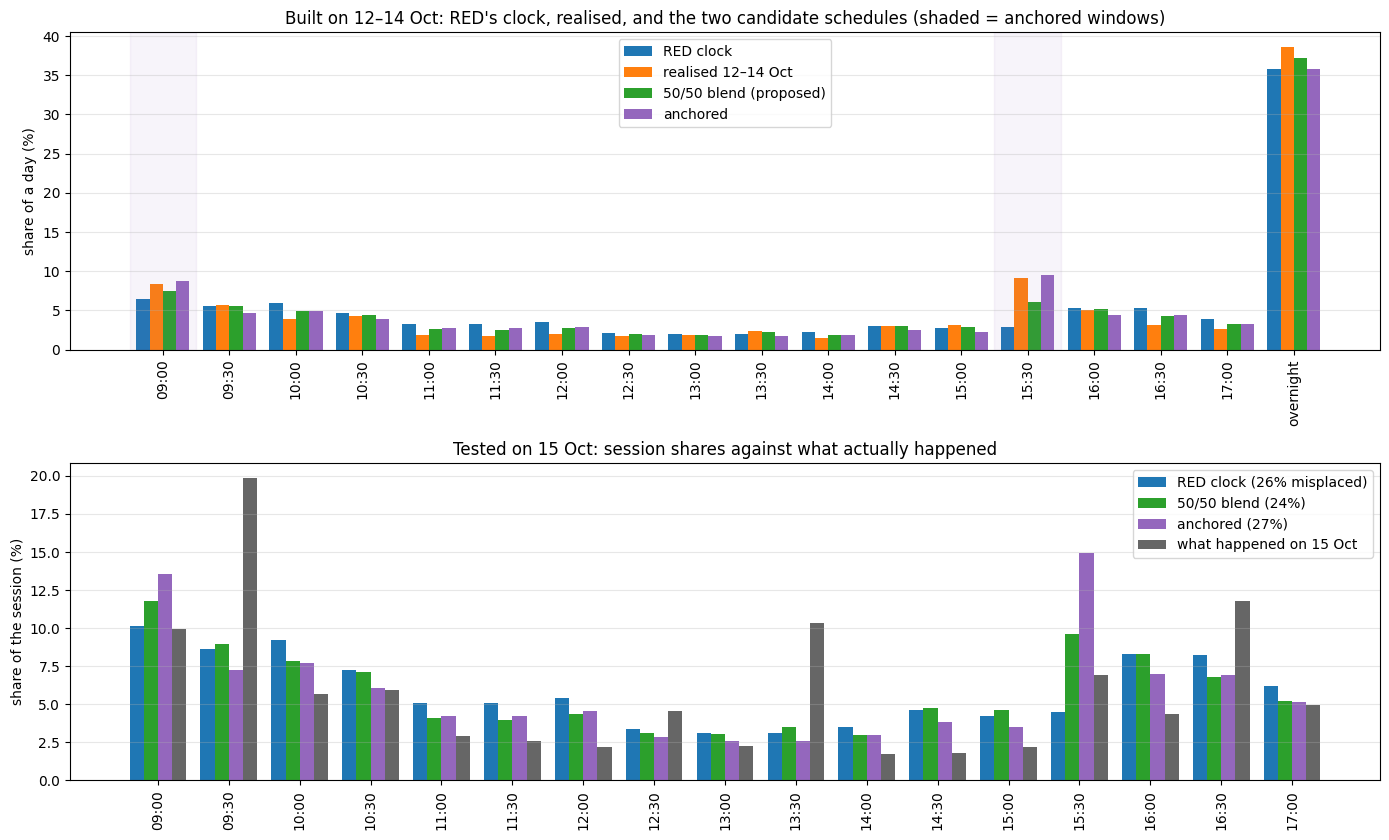

In [7]:
st["bucket"] = (st.index - pd.Timedelta(minutes=1)).floor("30min").strftime("%H:%M")
ok = st.r.abs() < 0.01
n_sessions = st.index.normalize().nunique()
b = st[ok].groupby("bucket").agg(desk=("dtte", "sum"), var=("r", lambda v: (v**2).sum())) / n_sessions
first, last = st.tte.groupby(st.index.date).first(), st.tte.groupby(st.index.date).last()
on_win = on[on.index.isin([str(d_) for d_ in first.index[1:]])]
b.loc["overnight"] = [(last.shift() - first).dropna().mean(), (on_win**2).mean()]
sched = pd.DataFrame({"desk_share": b.desk / b.desk.sum(), "realised_share": b["var"] / b["var"].sum()})
sched["suggested_share"] = 0.5 * sched.desk_share + 0.5 * sched.realised_share
session_buckets = [x_ for x_ in sched.index if x_ != "overnight"]
on_share = sched.loc["overnight", "desk_share"]

def desk_shape(days):
    s_ = st[np.isin(st.index.date, days)].groupby("bucket").dtte.sum().reindex(session_buckets); return s_ / s_.sum()
def realised_shape(days):
    x_ = st[np.isin(st.index.date, days) & (st.r.abs() < 0.01)]
    s_ = (x_.r**2).groupby(x_.bucket).sum().reindex(session_buckets).fillna(0); return s_ / s_.sum()
def anchors_of(days):
    ex_ = pd.DataFrame({str(d_): realised_shape([d_]) - desk_shape([d_]) for d_ in days}); return list(ex_.index[(ex_ > 0).all(axis=1)]), ex_
def anchored_shape(days):
    anc, desk, real = anchors_of(days)[0], desk_shape(days), realised_shape(days)
    if not anc: return desk
    rest = desk.drop(anc); rest = rest / rest.sum() * (1 - real[anc].sum())
    return pd.concat([real[anc], rest]).reindex(session_buckets)

all_days = sorted(set(st.index.date))
anchors, excess_by_day = anchors_of(all_days)
anc_full = anchored_shape(all_days) * (1 - on_share); anc_full.loc["overnight"] = on_share
sched["anchored_share"] = anc_full.reindex(sched.index)
sched["anchored_EUR"] = sched.anchored_share * theta_day
sched["RED_EUR"] = sched.desk_share * theta_day
sched["blend_EUR"] = sched.suggested_share * theta_day
print(sched.round(3)); print(f"\nAnchors: {anchors}\n", (excess_by_day * 100).round(1))

# ---- out-of-sample test: 15 Oct ----
test["r"] = np.log(test.spot).diff(); test["dtte"] = -test.tte.diff()
test["bucket"] = (test.index - pd.Timedelta(minutes=1)).floor("30min").strftime("%H:%M")
t_ok = test[test.r.abs() < 0.01]
t_var = (t_ok.r**2).groupby(t_ok.bucket).sum().reindex(session_buckets).fillna(0)
test_on_ret = np.log(test.spot.iloc[0] / ohlc.close_px.iloc[-1])            # 14 Oct close -> 15 Oct 09:05
test_on_tte = st.tte.iloc[-1] - test.tte.iloc[0]
truth_session = t_var / t_var.sum()
truth_full = pd.concat([t_var, pd.Series({"overnight": test_on_ret**2})]); truth_full = truth_full / truth_full.sum()
test_red_session = test.groupby("bucket").dtte.sum().reindex(session_buckets); test_red_session /= test_red_session.sum()
cands = {"RED clock": sched.desk_share, "realised 12–14 Oct": sched.realised_share, "50/50 blend": sched.suggested_share,
         "anchored": sched.anchored_share,
         "flat": pd.concat([pd.Series((1 - on_share) / len(session_buckets), index=session_buckets), pd.Series({"overnight": on_share})])}
def session_part(s_): s_ = s_.reindex(session_buckets); return s_ / s_.sum()
test_scores = pd.DataFrame({k: {"session only": 0.5 * (session_part(v) - truth_session).abs().sum(),
                                "full day incl. 14→15 Oct night": 0.5 * (v.reindex(truth_full.index) - truth_full).abs().sum()} for k, v in cands.items()}).T
print(f"\n15 Oct: overnight {test_on_ret:+.2%} (14 Oct close {ohlc.close_px.iloc[-1]:.2f} -> 09:05 {test.spot.iloc[0]:.3f}); session realised (RED clock) "
      f"{np.sqrt((t_ok.r**2).sum() / t_ok.dtte.sum()):.1%}; implied {test.ivol.mean():.1%}")
print("\nShare of theta in the wrong half-hour on 15 Oct (lower is better):\n", (test_scores * 100).round(1))
print("RED's clock on 15 Oct equals its 12-14 Oct shape:", np.allclose(test_red_session.values, session_part(sched.desk_share).values, atol=2e-3))

fig, (ax, az) = plt.subplots(2, 1, figsize=(14, 8.5))
xb = np.arange(len(sched)); w = .2
ax.bar(xb - 1.5 * w, sched.desk_share * 100, w, label="RED clock"); ax.bar(xb - .5 * w, sched.realised_share * 100, w, label="realised 12–14 Oct")
ax.bar(xb + .5 * w, sched.suggested_share * 100, w, label="50/50 blend (proposed)", color="C2"); ax.bar(xb + 1.5 * w, sched.anchored_share * 100, w, label="anchored", color="C4")
for a_n in anchors: ax.axvspan(list(sched.index).index(a_n) - .5, list(sched.index).index(a_n) + .5, color="C4", alpha=.07)
ax.set_xticks(xb); ax.set_xticklabels(sched.index, rotation=90); ax.set_ylabel("share of a day (%)"); ax.grid(alpha=.3, axis="y"); ax.legend()
ax.set_title("Built on 12–14 Oct: RED's clock, realised, and the two candidate schedules (shaded = anchored windows)")
xs = np.arange(len(session_buckets))
az.bar(xs - 1.5 * w, session_part(sched.desk_share) * 100, w, label=f"RED clock ({test_scores.loc['RED clock','session only']:.0%} misplaced)")
az.bar(xs - .5 * w, session_part(sched.suggested_share) * 100, w, color="C2", label=f"50/50 blend ({test_scores.loc['50/50 blend','session only']:.0%})")
az.bar(xs + .5 * w, session_part(sched.anchored_share) * 100, w, color="C4", label=f"anchored ({test_scores.loc['anchored','session only']:.0%})")
az.bar(xs + 1.5 * w, truth_session * 100, w, color="k", alpha=.6, label="what happened on 15 Oct")
az.set_xticks(xs); az.set_xticklabels(session_buckets, rotation=90); az.set_ylabel("share of the session (%)"); az.grid(alpha=.3, axis="y"); az.legend()
az.set_title("Tested on 15 Oct: session shares against what actually happened")
fig.tight_layout(); figs["theta"] = fig; plt.show()

## 6. Hedging schedule and PnL
**Actual path:** long 100 straddles from 09:05 on 12 Oct to the 14 Oct close. Every minute the straddles are marked at the desk's theo; at each rebalance the stock hedge is reset to −(desk delta × 10,000 shares).
* **option** = change in the straddles' value (same for every schedule); **hedge** = PnL on the stock hedge = Σ hedge position × price change; **costs** = shares traded × half the measured Xetra spread; **total** = option + hedge + costs; **rebalances** = number of hedge resets (the first one sets up the hedge).

**Monte Carlo:** 300 simulated three-day paths on the same 1,515 timestamps. Each minute the log price moves by σ·√∆tte·Z − ½σ²∆tte with Z standard normal and σ = the realised 22.2% (RED clock); the overnight step uses the tte RED burns overnight, so gaps are included. The straddles are marked with Black-76 at the starting implied vol (frozen, so no vega PnL), and every schedule is run on every path with the same costs.

Actual path, desk marks:
            option  hedge  costs   total  rebalances
1 min     -2822.0  632.0 -520.0 -2711.0      1515.0
10 min    -2822.0  584.0 -199.0 -2437.0       153.0
30 min    -2822.0  656.0 -111.0 -2277.0        51.0
1 hr      -2822.0  430.0  -68.0 -2461.0        27.0
3 hr      -2822.0  879.0  -49.0 -1992.0         9.0
suggested -2822.0  656.0 -125.0 -2291.0        69.0
no hedge  -2822.0 -206.0   -4.0 -3032.0         1.0

vega PnL €-2,250; 10 min − 3 hr €-445

Monte Carlo at 22.2%, implied frozen at 32.4%:
             mean    std     5%    50%    95%
1 min     -798.0  121.0 -915.0 -834.0 -580.0
10 min    -620.0  124.0 -759.0 -646.0 -387.0
30 min    -582.0  148.0 -757.0 -598.0 -329.0
1 hr      -569.0  159.0 -773.0 -594.0 -303.0
3 hr      -535.0  252.0 -829.0 -576.0   14.0
suggested -586.0  147.0 -759.0 -605.0 -339.0
no hedge  -517.0  772.0 -982.0 -798.0  723.0


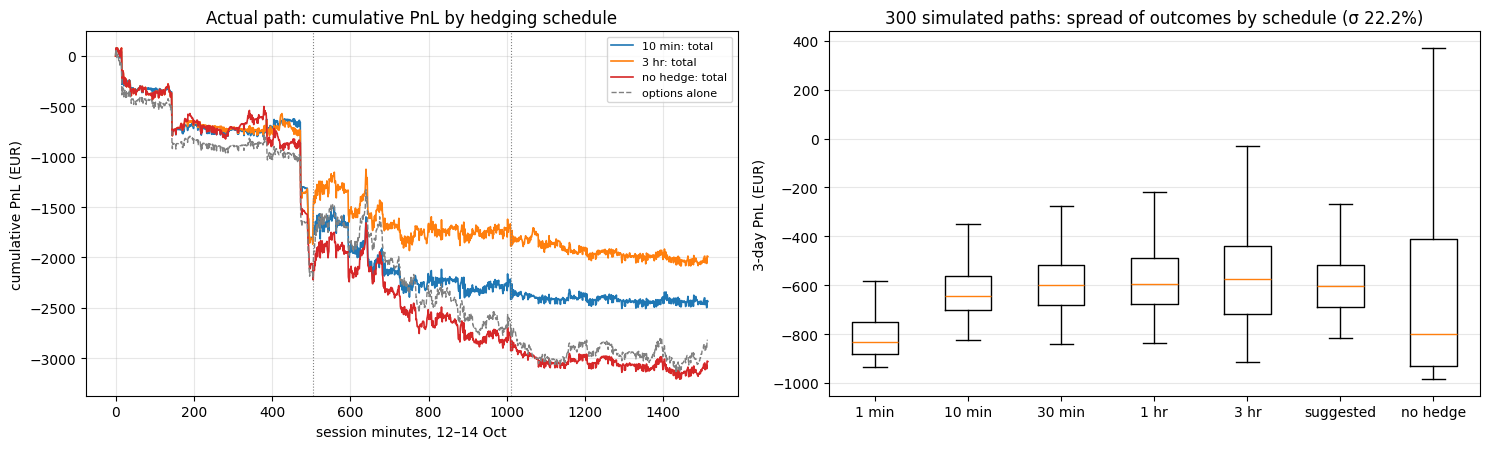

In [8]:
intervals = {"1 min": 1, "10 min": 10, "30 min": 30, "1 hr": 60, "3 hr": 180, "suggested": "suggested", "no hedge": None}
def rebal_mask(index, every):
    mins = np.asarray(index.hour * 60 + index.minute - 9 * 60)
    if every is None: return np.r_[True, np.zeros(len(index) - 1, bool)]
    if every == "suggested":   # 10 min 09:00-10:30 and 15:30-16:30, hourly otherwise
        busy = ((mins >= 0) & (mins < 90)) | ((mins >= 390) & (mins < 450))
        slot = np.where(busy, mins // 10, 1000 + mins // 60)
    else:
        slot = mins // every
    key = pd.Series(index.strftime("%Y%m%d")) + "_" + pd.Series(slot).astype(str)
    return (key != key.shift()).values
def hedge_path(price, delta_sh, S, index, every):
    rebal = rebal_mask(index, every)
    hedge = pd.Series(np.where(rebal, -N * delta_sh, np.nan)).ffill().values
    opt = N * (price - price[0]); hdg = np.r_[0, np.cumsum(hedge[:-1] * np.diff(S))]
    cost = -HALF_SPREAD * np.cumsum(np.abs(np.diff(np.r_[0, hedge])))
    return pd.DataFrame({"option": opt, "hedge": hdg, "costs": cost, "total": opt + hdg + cost}, index=index), int(rebal.sum())
def hedge_run(price, delta_sh, S, index, every):
    p, n = hedge_path(price, delta_sh, S, index, every); out = p.iloc[-1].to_dict(); out["rebalances"] = n; return out
def black76_run(df, every, freeze_vol=False):
    vol = np.full(len(df), df.ivol.iloc[0]) if freeze_vol else df.ivol.values
    g = black76(df.fwd.values, df.strike.iloc[0], df.tte.values, vol, df.interest_rate.values)
    return hedge_run(g["price"], g["delta"] * df.fwd.values / df.spot.values, df.spot.values, df.index, every)

res_desk = pd.DataFrame({k: hedge_run(sq.theo.values, sq.delta.values, st.spot.values, st.index, v) for k, v in intervals.items()}).T
res_bs = pd.DataFrame({k: black76_run(st, v) for k, v in intervals.items()}).T
res_frozen = pd.DataFrame({k: black76_run(st, v, True) for k, v in intervals.items()}).T
vega_pnl = res_bs.loc["no hedge", "option"] - res_frozen.loc["no hedge", "option"]
diff_10_3 = res_desk.loc["10 min", "total"] - res_desk.loc["3 hr", "total"]

def monte_carlo(sig, n_paths=300, seed=1):
    rng = np.random.default_rng(seed)
    dtte = np.r_[0, np.clip(-np.diff(st.tte.values), 0, None)]; ratio = (st.fwd / st.spot).values
    out = {k: [] for k in intervals}
    for _ in range(n_paths):
        S = st.spot.iloc[0] * np.exp(np.cumsum(sig * np.sqrt(dtte) * rng.standard_normal(len(st)) - 0.5 * sig**2 * dtte))
        sim = st.copy(); sim["spot"] = S; sim["fwd"] = S * ratio
        for k, v in intervals.items(): out[k].append(black76_run(sim, v, freeze_vol=True)["total"])
    return pd.DataFrame(out)
mc_vol = rv.loc["ALL", "30min RED clock"]; mc_paths = monte_carlo(mc_vol)
mc = mc_paths.describe(percentiles=[.05, .5, .95]).T[["mean", "std", "5%", "50%", "95%"]]
mc_cost = pd.Series({k: res_frozen.loc[k, "costs"] for k in intervals})
print("Actual path, desk marks:\n", res_desk.round(0)); print(f"\nvega PnL €{vega_pnl:,.0f}; 10 min − 3 hr €{diff_10_3:,.0f}")
print(f"\nMonte Carlo at {mc_vol:.1%}, implied frozen at {st.ivol.iloc[0]:.1%}:\n", mc.round(0))

fig, (ax, az) = plt.subplots(1, 2, figsize=(15, 4.6))
x_ = np.arange(len(st))
for k_, c_ in [("10 min", "C0"), ("3 hr", "C1"), ("no hedge", "C3")]:
    pth, _ = hedge_path(sq.theo.values, sq.delta.values, st.spot.values, st.index, intervals[k_])
    ax.plot(x_, pth.total.values, c=c_, lw=1.2, label=f"{k_}: total")
pth, _ = hedge_path(sq.theo.values, sq.delta.values, st.spot.values, st.index, None)
ax.plot(x_, pth.option.values, c="grey", lw=1, ls="--", label="options alone")
for i in np.flatnonzero(np.r_[False, st.index.date[1:] != st.index.date[:-1]]): ax.axvline(i, c="grey", ls=":", lw=.8)
ax.set_xlabel("session minutes, 12–14 Oct"); ax.set_ylabel("cumulative PnL (EUR)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title("Actual path: cumulative PnL by hedging schedule")
az.boxplot([mc_paths[k] for k in intervals], showfliers=False); az.set_xticks(range(1, len(intervals) + 1)); az.set_xticklabels(list(intervals))
az.set_ylabel("3-day PnL (EUR)"); az.grid(alpha=.3, axis="y")
az.set_title(f"300 simulated paths: spread of outcomes by schedule (σ {mc_vol:.1%})")
fig.tight_layout(); figs["mc"] = fig; plt.show()

## 7. Positions
The DTE positions sit in STOCKS_EUR on the arb network; that data was not available, so the brief's 100 straddles are used throughout.

## 8. ATM vol in each expiry
All listed expiries, with the ATM straddle price (Black-76 at the forward) and total variance σ²T. A later expiry must carry at least as much total variance as an earlier one; where it does not, the expiry is flagged (kept in every table and chart).

                expiry     tte      fwd  atm_vol  straddle_price  straddle_pct_fwd  total_var                                       calendar_check  2026-10-08  2026-10-09  2026-10-12  2026-10-13  2026-10-14  change 10-08→10-14 (pts)
term                                                                                                                                                                                                                                    
Oct-2026    2026-10-16  0.0053  26.0139   0.2748          0.4159            0.0160     0.0004                                                   ok      0.2448      0.3231      0.2522      0.2584      0.2708                    2.6046
Oct-2026 W4 2026-10-23  0.0249  26.0282   0.2576          0.8441            0.0324     0.0017                                                   ok      0.2771      0.3072      0.2798      0.2767      0.2545                   -2.2602
Oct-2026 W5 2026-10-30  0.0446  26.0425   0.2963          1.2975    

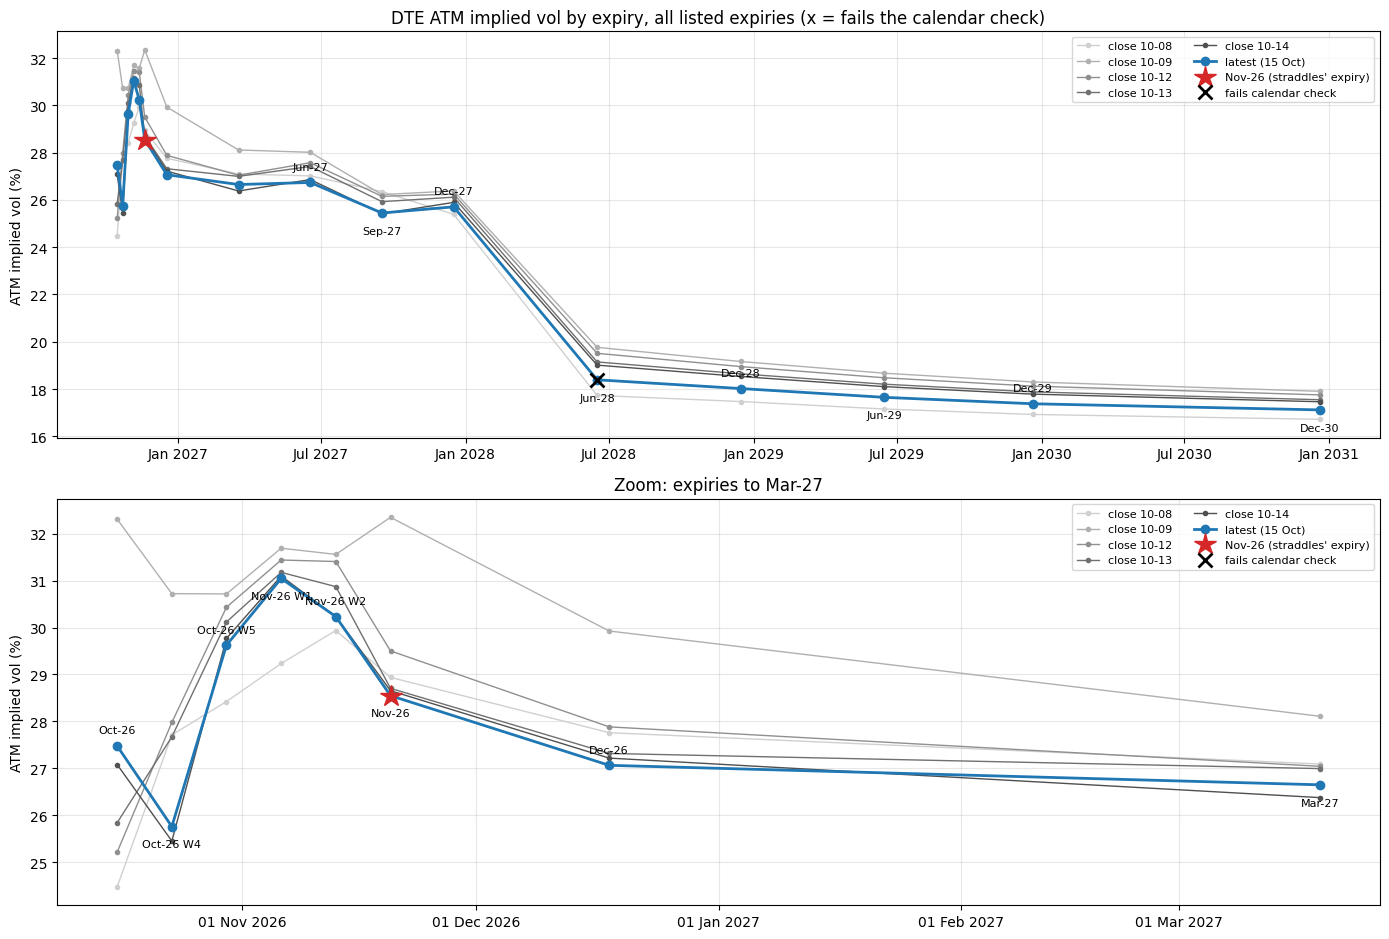

In [9]:
atm_curve = atm[~atm.index.str.contains("_")].copy()
atm_curve["expiry"] = atm_curve.index.map(expiry_date)
atm_curve["atm_vol"] = atm_curve.ivol_atm_000 / 100
atm_curve["total_var"] = atm_curve.atm_vol**2 * atm_curve.tte
atm_curve = atm_curve.sort_values("tte")
rates_ = fc.set_index("term").interest_rate
atm_curve["straddle_price"] = [black76(r.fwd, r.fwd, r.tte, r.atm_vol, rates_.get(t, rates_.median()))["price"] for t, r in atm_curve.iterrows()]
atm_curve["straddle_pct_fwd"] = atm_curve.straddle_price / atm_curve.fwd
atm_curve["calendar_check"] = np.where(atm_curve.total_var.diff() < 0, "FAILS: less total variance than the previous expiry", "ok")
bad_cal = atm_curve.total_var.diff() < 0
atm_by_close = atm_hist.pivot_table(index="term", columns="trade_date", values="ivol_atm_000") / 100
atm_by_close = atm_by_close.reindex([t for t in atm_curve.index if t in atm_by_close.index])
atm_table = atm_curve[["expiry", "tte", "fwd", "atm_vol", "straddle_price", "straddle_pct_fwd", "total_var", "calendar_check"]].join(atm_by_close)
chg_col = f"change {atm_by_close.columns[0][5:]}→{atm_by_close.columns[-1][5:]} (pts)"
atm_table[chg_col] = (atm_by_close.iloc[:, -1] - atm_by_close.iloc[:, 0]) * 100
print(atm_table.round(4).to_string())

def label_points(ax_, xs_, ys_, names, fs=8):
    for i, (x0, y0, nm) in enumerate(zip(xs_, ys_, names)):
        ax_.annotate(nm, (x0, y0), textcoords="offset points", xytext=(0, 9 if i % 2 == 0 else -15), ha="center", fontsize=fs)
fig, (ax, az) = plt.subplots(2, 1, figsize=(14, 9.5))
grey = ["#d0d0d0", "#b0b0b0", "#909090", "#707070", "#505050"]
for a2, end in [(ax, None), (az, pd.Timestamp("2027-04-01"))]:
    sub = atm_curve if end is None else atm_curve[atm_curve.expiry <= end]
    for col, c_ in zip(atm_by_close.columns, grey):
        h = atm_by_close.loc[[t for t in sub.index if t in atm_by_close.index], col]
        a2.plot(atm_curve.loc[h.index, "expiry"], h * 100, ".-", c=c_, lw=1, label=f"close {col[5:]}")
    a2.plot(sub.expiry, sub.atm_vol * 100, "o-", lw=2, c="C0", label=f"latest ({AS_OF:%d %b})")
    a2.plot(sub.loc[["Nov-2026"], "expiry"], sub.loc[["Nov-2026"], "atm_vol"] * 100, "*", ms=16, c="C3", label="Nov-26 (straddles' expiry)")
    bad = sub[sub.calendar_check != "ok"]
    a2.plot(bad.expiry, bad.atm_vol * 100, "x", ms=10, mew=2, c="k", label="fails calendar check")
    a2.set_ylabel("ATM implied vol (%)"); a2.grid(alpha=.3); a2.legend(fontsize=8, ncol=2)
label_points(az, atm_curve[atm_curve.expiry <= pd.Timestamp("2027-04-01")].expiry, atm_curve[atm_curve.expiry <= pd.Timestamp("2027-04-01")].atm_vol * 100,
             [short(t) for t in atm_curve[atm_curve.expiry <= pd.Timestamp("2027-04-01")].index])
label_points(ax, atm_curve[atm_curve.expiry > pd.Timestamp("2027-04-01")].expiry, atm_curve[atm_curve.expiry > pd.Timestamp("2027-04-01")].atm_vol * 100,
             [short(t) for t in atm_curve[atm_curve.expiry > pd.Timestamp("2027-04-01")].index])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); az.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
ax.set_title("DTE ATM implied vol by expiry, all listed expiries (x = fails the calendar check)")
az.set_title("Zoom: expiries to Mar-27"); fig.tight_layout(); figs["atm"] = fig; plt.show()

## 9. Vol curves by strike: shape and skew, all expiries
Vol at 90%/110% of the forward; risk reversal = vol(90%) − vol(110%); quadratic fit in log-moneyness k: slope (negative = put skew), slope×√T, curvature (positive = smile).
The fitting range widens with √T so long expiries, which have fewer strikes, can still be measured.

                tte  strikes used     atm  vol_90  vol_110  put_skew  call_skew  rr_90_110  slope_x_sqrtT  curvature
term                                                                                                                
Oct-2026     0.0077          35.0  0.2746  0.5637   0.4250    0.2891     0.1504     0.1387        -0.0388    12.4602
Oct-2026 W4  0.0273          33.0  0.2557  0.3817   0.3078    0.1260     0.0521     0.0739        -0.0414     6.5385
Oct-2026 W5  0.0470          33.0  0.2983  0.3806   0.3157    0.0823     0.0174     0.0649        -0.0557     4.1099
Nov-2026 W1  0.0666          32.0  0.3114  0.3705   0.3242    0.0592     0.0128     0.0463        -0.0502     2.9927
Nov-2026 W2  0.0858          32.0  0.3026  0.3489   0.3107    0.0463     0.0081     0.0382        -0.0482     2.3853
Nov-2026     0.1054          36.0  0.2868  0.3302   0.2907    0.0434     0.0039     0.0395        -0.0561     2.0574
Dec-2026     0.1804          37.0  0.2723  0.3037   0.2721    0.

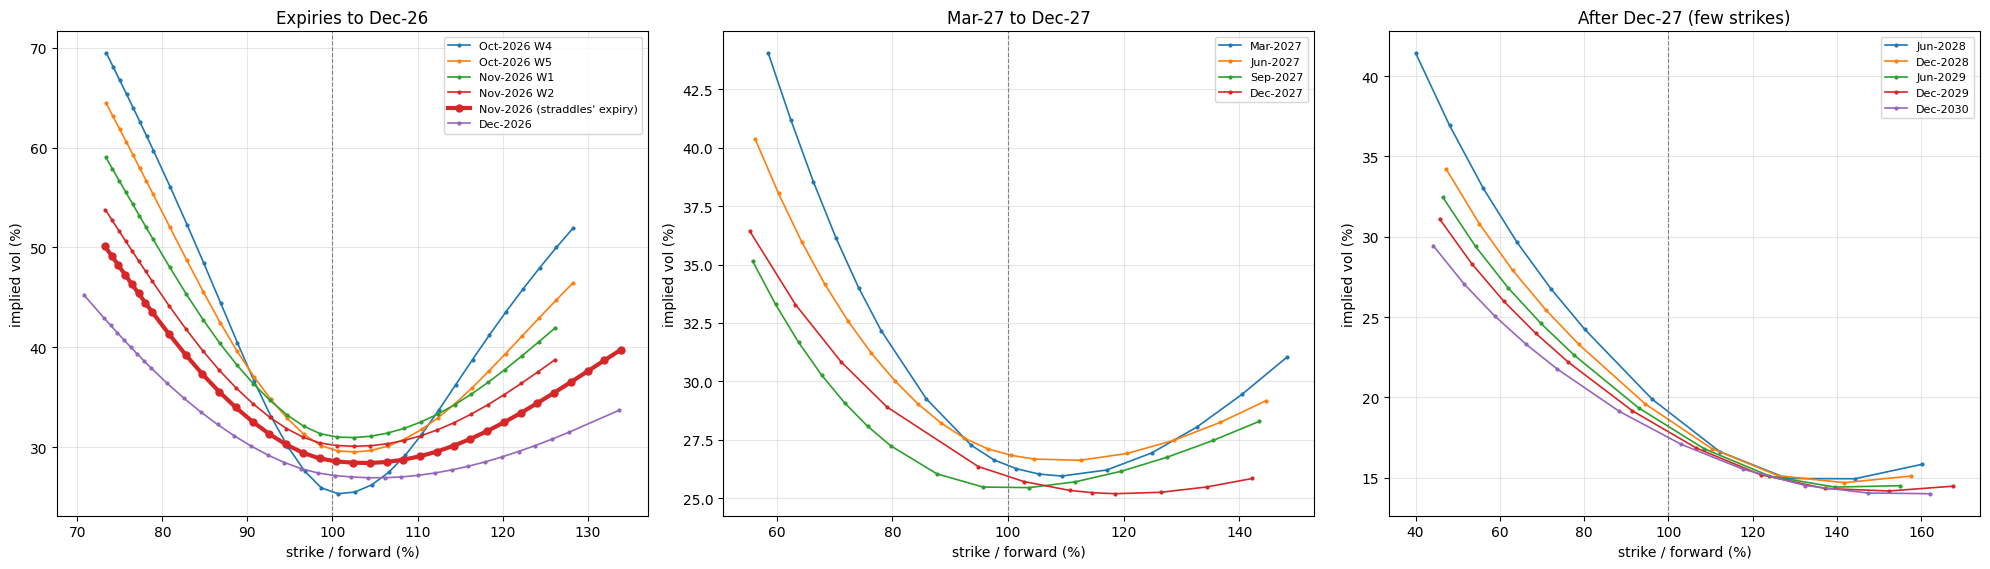

In [10]:
def smile_metrics(g):
    g = g.sort_values("strike"); k = np.log(g.strike.values / g.fwd.values); v = g.ivol.values / 100
    T = g.tte.iloc[0]; span = 0.35 * max(1.0, np.sqrt(T))
    keep = np.abs(k) <= span; k, v = k[keep], v[keep]
    if len(k) < 4: return None
    inside = lambda x: k.min() <= x <= k.max(); atm_v = np.interp(0.0, k, v)
    v90 = np.interp(np.log(0.9), k, v) if inside(np.log(0.9)) else np.nan
    v110 = np.interp(np.log(1.1), k, v) if inside(np.log(1.1)) else np.nan
    near = np.abs(k) <= 0.2 * max(1.0, np.sqrt(T))
    c2, b1, _ = np.polyfit(k[near], v[near], 2) if near.sum() >= 3 else (np.nan, np.nan, np.nan)
    return pd.Series({"tte": T, "strikes used": len(k), "atm": atm_v, "vol_90": v90, "vol_110": v110, "put_skew": v90 - atm_v, "call_skew": v110 - atm_v,
                      "rr_90_110": v90 - v110, "slope_x_sqrtT": b1 * np.sqrt(T), "curvature": c2})

sv_last = sv_hist[sv_hist.trade_date == sv_hist.trade_date.max()]
smiles = sv_last.groupby("term").apply(smile_metrics).dropna(how="all")
smiles = smiles.loc[smiles.tte.sort_values().index]
print(smiles.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))
groups = [("Expiries to Dec-26", lambda t: 0.01 < smiles.loc[t, "tte"] <= 0.2, (70, 135)),
          ("Mar-27 to Dec-27", lambda t: 0.2 < smiles.loc[t, "tte"] <= 1.2, (55, 150)),
          ("After Dec-27 (few strikes)", lambda t: smiles.loc[t, "tte"] > 1.2, (40, 170))]
for a2, (title, pick, xr) in zip(axes, groups):
    for t in [t for t in smiles.index if pick(t)]:
        g = sv_last[sv_last.term == t].sort_values("strike"); m = g.strike / g.fwd * 100; k_ = (m > xr[0]) & (m < xr[1])
        hl = t == "Nov-2026"
        a2.plot(m[k_], g.ivol[k_], "o-" if hl else ".-", lw=3 if hl else 1.2, ms=5 if hl else 4, c="C3" if hl else None,
                label=t + (" (straddles' expiry)" if hl else ""), zorder=5 if hl else 2)
    a2.axvline(100, c="grey", ls="--", lw=.8); a2.set_xlabel("strike / forward (%)"); a2.set_ylabel("implied vol (%)")
    a2.set_title(title); a2.grid(alpha=.3); a2.legend(fontsize=8)
fig.tight_layout(); figs["smiles"] = fig; plt.show()

## 10. How the vol curves changed over 5 days, and the Nov-26 story

ATM by close:
 trade_date   2026-10-08  2026-10-09  2026-10-12  2026-10-13  2026-10-14
term                                                                   
Oct-2026          24.48       32.31       25.22       25.84       27.08
Oct-2026 W4       27.71       30.72       27.98       27.67       25.45
Oct-2026 W5       28.42       30.72       30.43       30.12       29.77
Nov-2026 W1       29.23       31.69       31.44       31.18       31.10
Nov-2026 W2       29.94       31.56       31.41       30.87       30.23
Nov-2026          28.94       32.35       29.50       28.70       28.65
Dec-2026          27.76       29.93       27.88       27.32       27.22
Mar-2027          27.09       28.11       27.04       26.99       26.38
Jun-2027          27.02       28.01       27.57       27.41       26.86
Sep-2027          26.35       26.22       26.15       25.93       25.41
Dec-2027          25.39       26.38       26.24       26.11       25.89
Jun-2028          17.73       19.76       19.51  

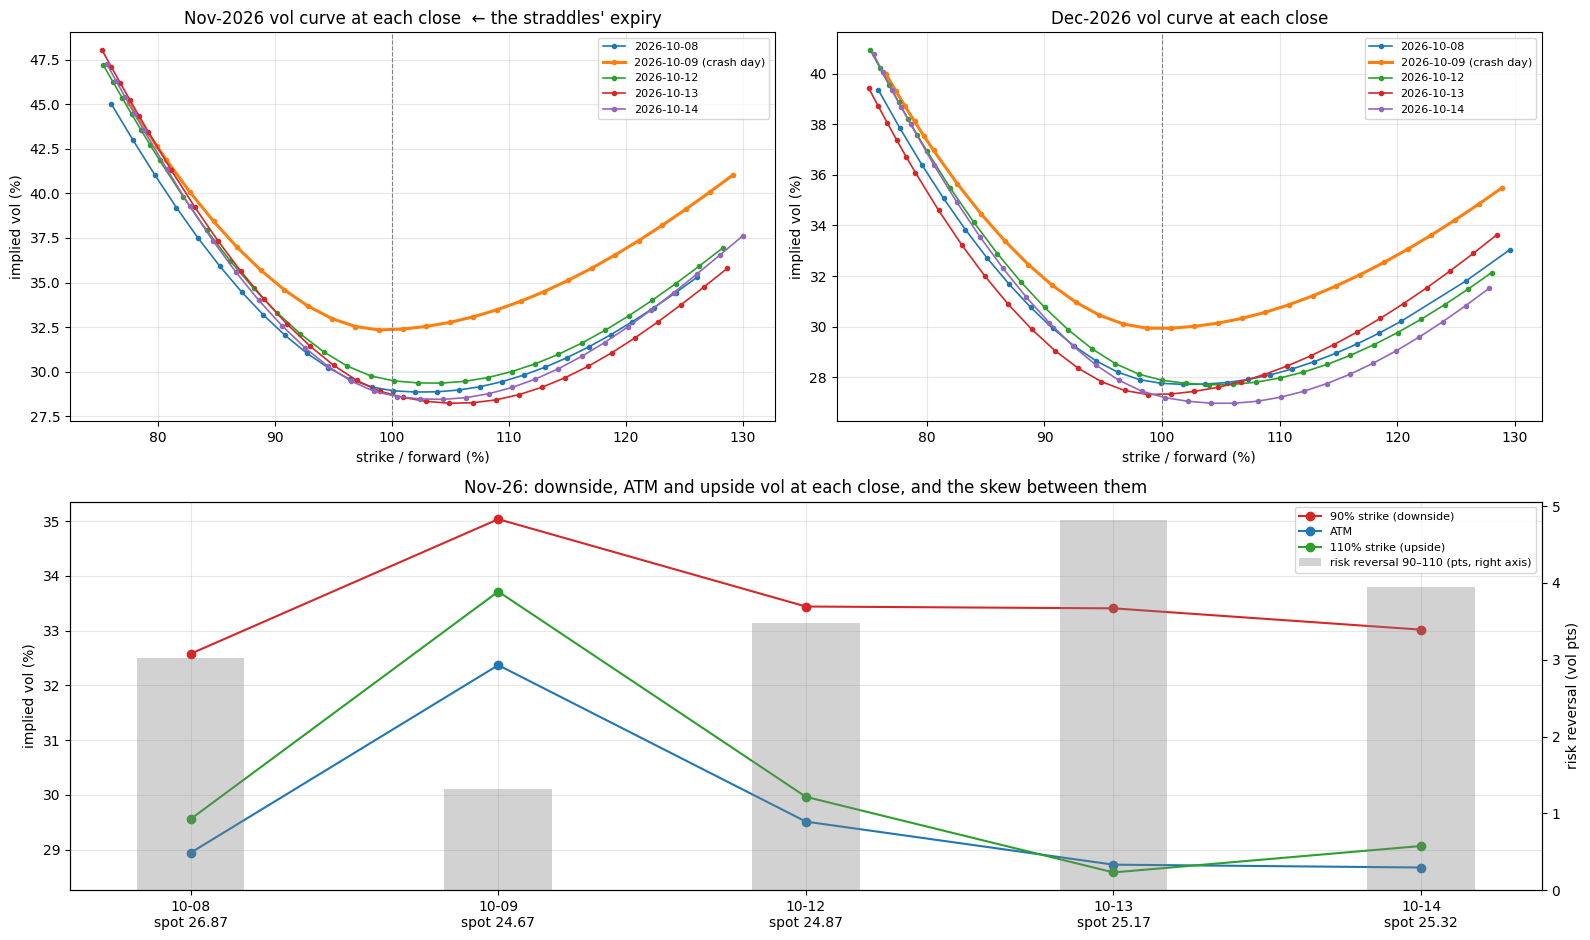

In [11]:
hist_metrics = sv_hist.groupby(["trade_date", "term"]).apply(smile_metrics).dropna(how="all").reset_index()
rr_by_close = hist_metrics.pivot(index="term", columns="trade_date", values="rr_90_110").reindex(atm_curve.index).dropna(how="all")
nov_story = hist_metrics[hist_metrics.term == "Nov-2026"].set_index("trade_date")[["atm", "vol_90", "vol_110", "rr_90_110"]]
nov_story["spot (close)"] = dc.reindex(pd.to_datetime(nov_story.index)).values
print("ATM by close:\n", (atm_by_close * 100).round(2)); print("\nRR by close (pts):\n", (rr_by_close * 100).round(2)); print("\nNov-26:\n", nov_story.round(4))
fig = plt.figure(figsize=(16, 9.5)); gs = fig.add_gridspec(2, 2)
for j, t in enumerate(["Nov-2026", "Dec-2026"]):
    a2 = fig.add_subplot(gs[0, j])
    for d_ in sorted(sv_hist.trade_date.unique()):
        g = sv_hist[(sv_hist.trade_date == d_) & (sv_hist.term == t)].sort_values("strike"); m = g.strike / g.fwd; k_ = (m > 0.75) & (m < 1.3)
        a2.plot(m[k_] * 100, g.ivol[k_], ".-", lw=2.2 if d_ == "2026-10-09" else 1.2, label=d_ + (" (crash day)" if d_ == "2026-10-09" else ""))
    a2.axvline(100, c="grey", ls="--", lw=.8); a2.set_title(f"{t} vol curve at each close" + ("  ← the straddles' expiry" if t == "Nov-2026" else ""))
    a2.set_xlabel("strike / forward (%)"); a2.set_ylabel("implied vol (%)"); a2.grid(alpha=.3); a2.legend(fontsize=8)
a2 = fig.add_subplot(gs[1, :]); xs_ = np.arange(len(nov_story))
for col, lab, c_ in [("vol_90", "90% strike (downside)", "C3"), ("atm", "ATM", "C0"), ("vol_110", "110% strike (upside)", "C2")]:
    a2.plot(xs_, nov_story[col] * 100, "o-", c=c_, label=lab)
a3 = a2.twinx(); a3.bar(xs_, nov_story.rr_90_110 * 100, .35, color="grey", alpha=.35, label="risk reversal 90–110 (pts, right axis)")
a2.set_xticks(xs_); a2.set_xticklabels([f"{d_[5:]}\nspot {s_:.2f}" for d_, s_ in zip(nov_story.index, nov_story["spot (close)"])])
a2.set_ylabel("implied vol (%)"); a3.set_ylabel("risk reversal (vol pts)"); a2.grid(alpha=.3)
h1, l1 = a2.get_legend_handles_labels(); h2, l2 = a3.get_legend_handles_labels(); a2.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper right")
a2.set_title("Nov-26: downside, ATM and upside vol at each close, and the skew between them")
fig.tight_layout(); figs["smile_hist"] = fig; plt.show()

## 11. Forward vol curve, events, and the non-event base
Forward variance between expiries = (σ₂²T₂ − σ₁²T₁)/(T₂ − T₁), for **every** listed expiry; windows where it is negative (the calendar-check failures from section 8) are flagged and have no forward vol.
Base = median forward vol of event-free windows to Dec-26 (≥ ~2.5 days). Event variance = (window forward variance − base²) × window length.
Events up to Dec-26 come from `events.csv` (sourced); later ones fall in long windows and are listed only. The ATM curve is then rebuilt with each event switched off in turn.

Base 25.08% from ['Oct-2026 W4', 'Nov-2026 W2', 'Nov-2026', 'Dec-2026']
  from_term     to_term  trading_days  fwd_vol  event_move  event_days                                    note                             events
      today    Oct-2026        1.3832   0.2748      0.0000      0.0000                                                                           
   Oct-2026 Oct-2026 W4        5.1004   0.2527      0.0000      0.0000                                                                           
Oct-2026 W4 Oct-2026 W5        5.1004   0.3391      0.0320      4.2247                                   event 29 Oct T-Mobile US Q3 2026 results
Oct-2026 W5 Nov-2026 W1        5.1004   0.3405      0.0323      4.3026                                   event         05 Nov DTE Q3 2026 results
Nov-2026 W1 Nov-2026 W2        5.0004   0.2735      0.0000      0.0000                                                                           
Nov-2026 W2    Nov-2026        5.1004   0.1985      

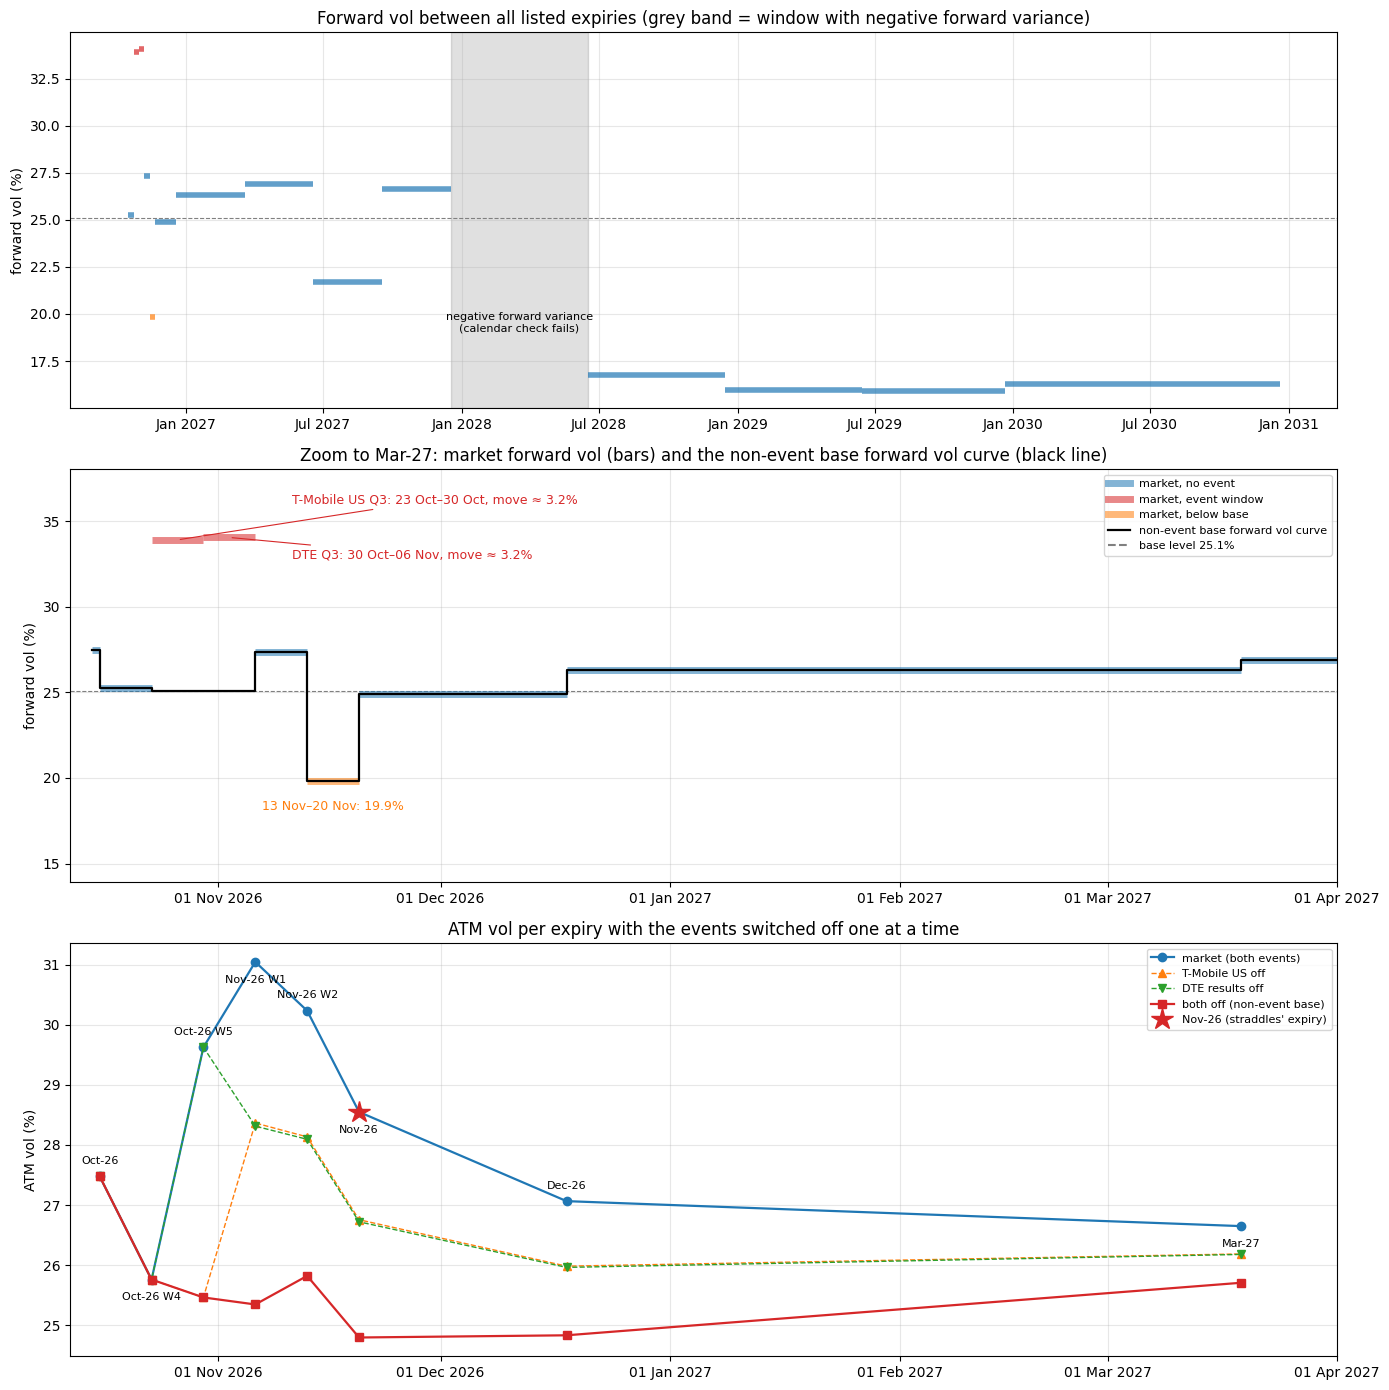

In [12]:
fv = pd.DataFrame({"from": [AS_OF] + list(atm_curve.expiry.iloc[:-1]), "to": atm_curve.expiry.values,
                   "from_term": ["today"] + list(atm_curve.index[:-1]), "to_term": atm_curve.index,
                   "dT": np.r_[atm_curve.tte.iloc[0], np.diff(atm_curve.tte.values)], "dVar": np.r_[atm_curve.total_var.iloc[0], np.diff(atm_curve.total_var.values)]})
fv["fwd_var"] = fv.dVar / fv.dT
fv["fwd_vol"] = np.where(fv.fwd_var > 0, np.sqrt(fv.fwd_var.clip(lower=0)), np.nan); fv["trading_days"] = fv.dT / TTE_PER_DAY
future_ev = ev[(ev.event_date >= AS_OF) & (ev.event_date <= pd.Timestamp("2026-12-31"))]
fv["events"] = fv.apply(lambda r: "; ".join(f"{d_:%d %b} {e}" for d_, e in zip(future_ev.event_date, future_ev.event) if r["from"] < d_ <= r["to"]), axis=1)
fv["has_event"] = fv.events != ""
base_pool = fv[(~fv.has_event) & (fv.dT >= 0.01) & (fv.to <= pd.Timestamp("2026-12-31"))]
BASE_VOL = base_pool.fwd_vol.median()
fv["base_fwd_vol"] = np.where(fv.has_event, BASE_VOL, fv.fwd_vol)
fv["event_var"] = np.where(fv.has_event, (fv.fwd_var - BASE_VOL**2).clip(lower=0) * fv.dT, 0.0)
fv["event_move"] = np.sqrt(fv.event_var); fv["event_days"] = fv.event_var / (BASE_VOL**2 * TTE_PER_DAY)
fv["note"] = np.where(fv.fwd_var <= 0, "inconsistent: negative forward variance",
             np.where(fv.has_event, "event", np.where((fv.fwd_vol < 0.85 * BASE_VOL) & (fv.dT >= 0.01) & (fv.to <= pd.Timestamp("2027-12-31")), "low vs base", "")))
dte_ev = fv[fv.events.str.contains("DTE")].iloc[0]; tm_ev = fv[fv.events.str.contains("T-Mobile")].iloc[0]

# ATM curves with events switched off
def rebuilt_atm(drop):
    fvar = np.where(fv.events.str.contains("|".join(drop)) & fv.has_event, BASE_VOL**2, fv.fwd_var) if drop else fv.fwd_var.values
    return np.sqrt(np.clip(np.cumsum(fvar * fv.dT.values), 0, None) / atm_curve.tte.values)
events_off = pd.DataFrame({"market (both events)": atm_curve.atm_vol.values,
                           "T-Mobile US off": rebuilt_atm(["T-Mobile"]), "DTE results off": rebuilt_atm(["DTE"]),
                           "both off (non-event base)": rebuilt_atm(["T-Mobile", "DTE"])}, index=atm_curve.index)
base_curve = atm_curve[["expiry", "tte", "atm_vol"]].copy()
base_curve["base_atm_vol"] = events_off["both off (non-event base)"]
base_curve["event_premium_pts"] = (base_curve.atm_vol - base_curve.base_atm_vol) * 100
print(f"Base {BASE_VOL:.2%} from {list(base_pool.to_term)}")
print(fv[["from_term", "to_term", "trading_days", "fwd_vol", "event_move", "event_days", "note", "events"]].round(4).to_string(index=False))
print("\n", (events_off * 100).round(2).to_string())

from matplotlib.lines import Line2D
fig, (a0, ax, az) = plt.subplots(3, 1, figsize=(14, 14), gridspec_kw={"height_ratios": [1, 1.1, 1.1]})
for _, r in fv.iterrows():   # full curve
    if pd.notna(r.fwd_vol):
        a0.hlines(r.fwd_vol * 100, r["from"], r["to"], lw=4, color="C3" if r.has_event else ("C1" if r.note == "low vs base" else "C0"), alpha=.7)
    else:
        a0.axvspan(r["from"], r["to"], color="k", alpha=.12)
        a0.annotate("negative forward variance\n(calendar check fails)", (r["from"] + (r["to"] - r["from"]) / 2, BASE_VOL * 100 - 6), ha="center", fontsize=8)
a0.axhline(BASE_VOL * 100, c="grey", ls="--", lw=.8); a0.set_ylabel("forward vol (%)"); a0.grid(alpha=.3)
a0.set_title("Forward vol between all listed expiries (grey band = window with negative forward variance)")
a0.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
steps_x = list(fv["from"]) + [fv["to"].iloc[-1]]; steps_y = list(fv.base_fwd_vol * 100) + [fv.base_fwd_vol.iloc[-1] * 100]
ax.step(steps_x, steps_y, where="post", color="k", lw=1.6, zorder=4)
n_ev = 0
for _, r in fv.iterrows():
    if pd.isna(r.fwd_vol): continue
    ax.hlines(r.fwd_vol * 100, r["from"], r["to"], lw=5, color="C3" if r.has_event else ("C1" if r.note == "low vs base" else "C0"), alpha=.55, zorder=3)
    if r.has_event:
        label = re.sub(r" (20\d\d )?results", "", r.events[7:]).split(";")[0]
        lab_x = fv[fv.has_event]["to"].max() + pd.Timedelta(days=5); lab_y = fv.fwd_vol.max() * 100 + 2.2 - 3.2 * n_ev
        ax.annotate(f"{label}: {r['from']:%d %b}–{r['to']:%d %b}, move ≈ {r.event_move:.1%}", (r["from"] + (r["to"] - r["from"]) / 2, r.fwd_vol * 100),
                    xytext=(lab_x, lab_y), textcoords="data", ha="left", va="center", fontsize=9, color="C3", arrowprops=dict(arrowstyle="-", color="C3", lw=.8))
        n_ev += 1
    elif r.note == "low vs base":
        ax.annotate(f"{r['from']:%d %b}–{r['to']:%d %b}: {r.fwd_vol:.1%}", (r["from"] + (r["to"] - r["from"]) / 2, r.fwd_vol * 100),
                    textcoords="offset points", xytext=(0, -14), ha="center", va="top", fontsize=9, color="C1")
ax.axhline(BASE_VOL * 100, c="grey", lw=.8, ls="--"); ax.set_xlim(AS_OF - pd.Timedelta(days=3), pd.Timestamp("2027-04-01"))
ax.set_ylim(np.nanmin(fv.fwd_vol) * 100 - 2, np.nanmax(fv.fwd_vol) * 100 + 4); ax.set_ylabel("forward vol (%)"); ax.grid(alpha=.3)
ax.set_title("Zoom to Mar-27: market forward vol (bars) and the non-event base forward vol curve (black line)")
ax.legend(handles=[Line2D([], [], c="C0", lw=5, alpha=.55, label="market, no event"), Line2D([], [], c="C3", lw=5, alpha=.55, label="market, event window"),
                   Line2D([], [], c="C1", lw=5, alpha=.55, label="market, below base"), Line2D([], [], c="k", lw=1.6, label="non-event base forward vol curve"),
                   Line2D([], [], c="grey", ls="--", label=f"base level {BASE_VOL:.1%}")], loc="upper right", fontsize=8)
zoom = atm_curve.expiry <= pd.Timestamp("2027-04-01")
for col, sty in [("market (both events)", "o-"), ("T-Mobile US off", "^--"), ("DTE results off", "v--"), ("both off (non-event base)", "s-")]:
    az.plot(atm_curve.expiry[zoom], events_off.loc[zoom, col] * 100, sty, lw=1.6 if col.startswith(("market", "both")) else 1, label=col)
az.plot(atm_curve.loc[["Nov-2026"], "expiry"], atm_curve.loc[["Nov-2026"], "atm_vol"] * 100, "*", ms=16, c="C3", label="Nov-26 (straddles' expiry)")
label_points(az, atm_curve.expiry[zoom], events_off.loc[zoom, "market (both events)"] * 100, [short(t) for t in atm_curve.index[zoom]])
az.set_xlim(AS_OF - pd.Timedelta(days=3), pd.Timestamp("2027-04-01")); az.set_ylabel("ATM vol (%)"); az.grid(alpha=.3); az.legend(fontsize=8)
az.set_title("ATM vol per expiry with the events switched off one at a time")
for a2 in (ax, az): a2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
fig.tight_layout(); figs["fwdvol"] = fig; plt.show()

## 12. Realised vol over the last year, past event moves, and Mako's event table
Close-to-close on RED's clock (variance per weekday ÷ tte per weekday). Past event days removed; the largest day shown separately; typical day = median |return| ÷ 0.6745 (robust to single jumps).
Past results days: the larger of the day and the next day for T-Mobile US (timing varies). Mako's event table is compared with the sourced dates.

Largest move: Fri 09 Oct 2026 -8.54%
          events removed  also without 09 Oct  typical day (median-based)  days with |move| > 3%
10 days         0.473431             0.195501                    0.268778                    1.0
20 days         0.392744             0.250007                    0.245676                    2.0
60 days         0.313939             0.260901                    0.246007                    5.0
120 days        0.310256             0.284822                    0.247751                   13.0
250 days        0.274140             0.260451                    0.208498                   19.0

       date                       event    move  abs_move                                              source
2025-10-23 T-Mobile US Q3 2025 results -0.0229    0.0229                           Benzinga earnings history
2025-11-13         DTE Q3 2025 results -0.0037    0.0037                  Nordnet corporate-actions calendar
2026-02-11 T-Mobile US Q4 2025 results  0.0512    0.

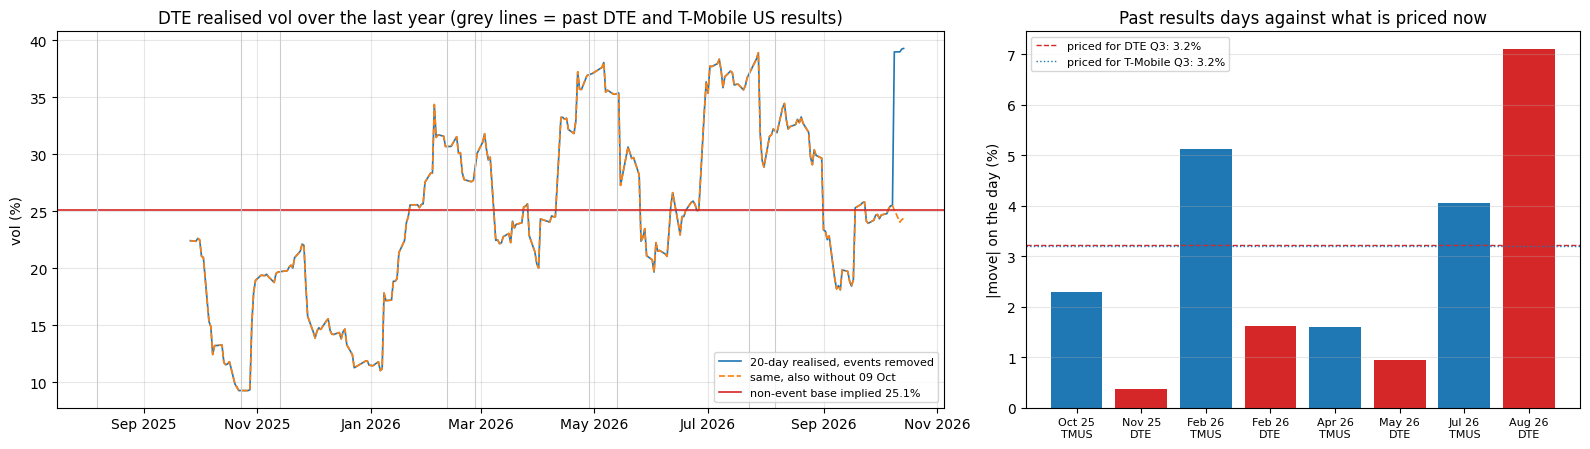

In [13]:
rets_all = np.log(dc).diff().dropna()
shock_day = rets_all.abs().idxmax()
past_ev = ev[ev.event_date < AS_OF]
event_days_set = set(past_ev.event_date) | {d_ + BDay(1) for d_ in past_ev[past_ev.event.str.contains("T-Mobile")].event_date}
clean_all = rets_all[~rets_all.index.isin(event_days_set)]
red_clock = lambda x_: np.sqrt((x_**2).mean() / TTE_PER_DAY)
ext = f"also without {shock_day:%d %b}"
regime = pd.DataFrame({f"{n} days": {"events removed": red_clock(clean_all.iloc[-n:]), ext: red_clock(clean_all.iloc[-n:].drop(shock_day, errors="ignore")),
                                      "typical day (median-based)": clean_all.iloc[-n:].abs().median() / 0.6745 / np.sqrt(TTE_PER_DAY),
                                      "days with |move| > 3%": (clean_all.iloc[-n:].abs() > 0.03).sum()} for n in (10, 20, 60, 120, 250)}).T
rows = []
for _, e in past_ev.iterrows():
    days_ = [e.event_date] + ([e.event_date + BDay(1)] if "T-Mobile" in e.event else [])
    r_ = rets_all.reindex(days_).dropna()
    if len(r_): rows.append({"date": e.event_date.date(), "event": e.event, "move": r_.loc[r_.abs().idxmax()], "abs_move": r_.abs().max(), "source": e.source})
past_moves = pd.DataFrame(rows)
hist_rms = {who: np.sqrt((past_moves[past_moves.event.str.contains(who)].abs_move**2).mean()) for who in ["DTE", "T-Mobile"]}
hist_med = {who: past_moves[past_moves.event.str.contains(who)].abs_move.median() for who in ["DTE", "T-Mobile"]}
typical = regime.loc["60 days", "typical day (median-based)"]; ex_shock = regime.loc["60 days", ext]

mk_ = mk.assign(event_date=pd.to_datetime(mk.term_timestamp.str.replace(" UTC", ""), utc=True).dt.tz_convert(TZ).dt.tz_localize(None).dt.normalize(),
                last_updated=pd.to_datetime(mk.update_timestamp.str.replace(" UTC", "")).dt.strftime("%d %b %Y"))
dte_src = ev[ev.event.str.startswith("DTE")].reset_index(drop=True)
def actual_date(d):
    gap = (dte_src.event_date - d).abs(); return dte_src.event_date[gap.idxmin()] if gap.min() <= pd.Timedelta(days=21) else pd.NaT
mako_cmp = mk_[["event_date", "vol_region", "detail", "event_value", "certainty", "modifier", "last_updated"]].sort_values("event_date").reset_index(drop=True)
mako_cmp["sourced date"] = mako_cmp.event_date.map(actual_date)
mako_cmp["days off"] = (mako_cmp.event_date - mako_cmp["sourced date"]).dt.days
mako_q3 = mako_cmp[(mako_cmp.event_date.dt.year == 2026) & (mako_cmp.event_date.dt.month == 11) & (mako_cmp.vol_region == "RED_DTE")].iloc[0]
mako_has_tmus = mk.symbol.str.contains("TMUS").any() or mk.detail.str.contains("T-Mobile|TMUS", case=False).any()
mako_stale = (pd.to_datetime(mk_.update_timestamp.str.replace(" UTC", "")) < pd.Timestamp("2025-01-01")).sum()
print(f"Largest move: {shock_day:%a %d %b %Y} {rets_all[shock_day]:+.2%}"); print(regime); print("\n", past_moves.round(4).to_string(index=False))
print(hist_rms, hist_med); print("\n", mako_cmp.to_string(index=False))

roll = lambda s_: s_.pow(2).rolling(20).mean().div(TTE_PER_DAY).pow(0.5)
fig, (ax, az) = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax.plot(roll(clean_all) * 100, lw=1.2, label="20-day realised, events removed")
ax.plot(roll(clean_all.drop(shock_day)) * 100, lw=1.2, ls="--", label=f"same, also without {shock_day:%d %b}")
ax.axhline(BASE_VOL * 100, c="C3", lw=1.2, label=f"non-event base implied {BASE_VOL:.1%}")
for d_ in past_ev.event_date: ax.axvline(d_, c="#ccc", lw=.8)
ax.set_ylabel("vol (%)"); ax.grid(alpha=.3); ax.legend(fontsize=8); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("DTE realised vol over the last year (grey lines = past DTE and T-Mobile US results)")
pm = past_moves.sort_values("date"); cols_ = ["C3" if "DTE" in e else "C0" for e in pm.event]
az.bar(range(len(pm)), pm.abs_move * 100, color=cols_)
az.axhline(dte_ev.event_move * 100, c="C3", ls="--", lw=1, label=f"priced for DTE Q3: {dte_ev.event_move:.1%}")
az.axhline(tm_ev.event_move * 100, c="C0", ls=":", lw=1, label=f"priced for T-Mobile Q3: {tm_ev.event_move:.1%}")
az.set_xticks(range(len(pm))); az.set_xticklabels([f"{d:%b %y}\n{'DTE' if 'DTE' in e else 'TMUS'}" for d, e in zip(pm.date, pm.event)], fontsize=8)
az.set_ylabel("|move| on the day (%)"); az.grid(alpha=.3, axis="y"); az.legend(fontsize=8); az.set_title("Past results days against what is priced now")
fig.tight_layout(); figs["realised"] = fig; plt.show()

## 13. The trade
Buy the window priced below the base with a gamma-neutral calendar: long the later expiry, short enough of the earlier one that gammas cancel at inception; what is left is mostly the vol of the window between them.
Below: the two legs and the net greeks, the PnL at the short leg's expiry against the stock price, and the PnL against the vol the window is finally priced at.

                      strike (≈ forward)   vol  price per straddle  premium (EUR)  delta (shares)  gamma (shares per 1%)  vega (EUR/pt)  theta (EUR/day)
long 100 Nov-2026                  26.09  0.29                1.90       19008.27          364.35                 867.32         665.35          -355.91
short 95 Nov-2026 W2               26.07  0.30                1.81      -17238.10         -330.60                -866.85        -569.81           400.06
net                                  NaN   NaN                 NaN        1770.17           33.75                   0.47          95.54            44.15

window 13 Nov-20 Nov at 19.9% vs base 25.1%; gain if base €514; breakeven week vol 6.1%; stock breakevens at 13 Nov: [25.45 26.75]
before results (04 Nov close): net gamma -255 shares per 1%; gamma-neutral short count 80; PnL of a 3.2% gap €-346


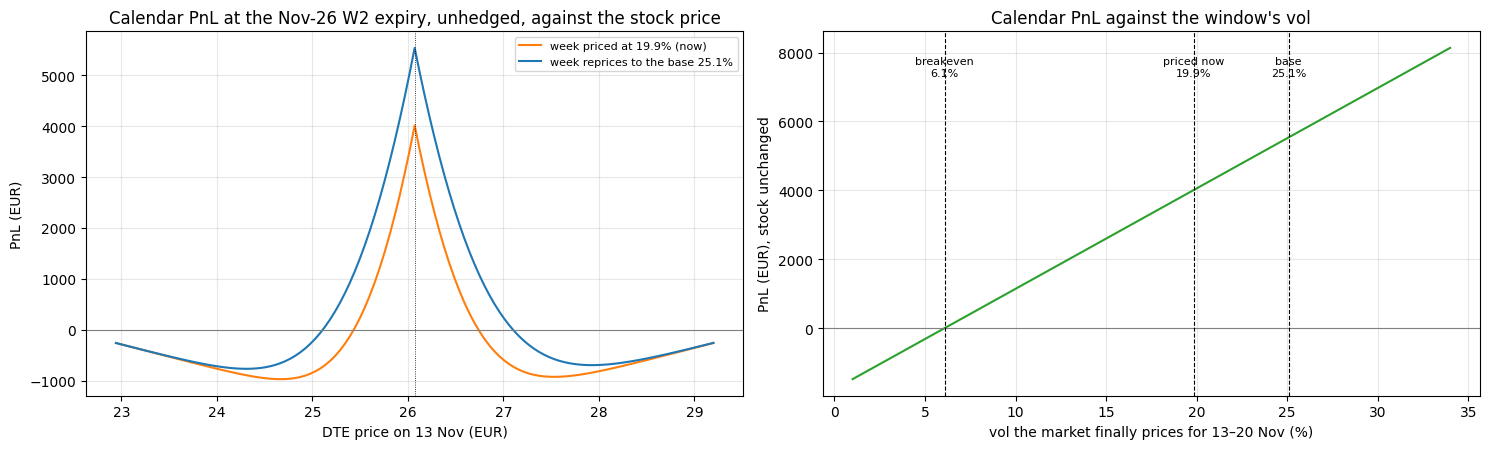

In [14]:
def atm_straddle(term):
    r_ = atm_curve.loc[term]; rate = fc.set_index("term").interest_rate.get(term, fc.interest_rate.median())
    return black76(r_.fwd, r_.fwd, r_.tte, r_.atm_vol, rate), r_, rate
cheap = fv[fv.note == "low vs base"].iloc[0]
long_term, short_term = cheap.to_term, cheap.from_term
gL, rL, rateL = atm_straddle(long_term); gS, rS, rateS = atm_straddle(short_term)
n_long = 100; n_short = n_long * gL["gamma"] / gS["gamma"]
legs = pd.DataFrame({f"long {n_long} {long_term}": {"strike (≈ forward)": rL.fwd, "vol": rL.atm_vol, "price per straddle": gL["price"],
                         "premium (EUR)": CONTRACT_SIZE * n_long * gL["price"], "delta (shares)": CONTRACT_SIZE * n_long * gL["delta"],
                         "gamma (shares per 1%)": CONTRACT_SIZE * n_long * gL["gamma"] * rL.fwd * 0.01, "vega (EUR/pt)": CONTRACT_SIZE * n_long * gL["vega"] / 100},
                     f"short {n_short:.0f} {short_term}": {"strike (≈ forward)": rS.fwd, "vol": rS.atm_vol, "price per straddle": gS["price"],
                         "premium (EUR)": -CONTRACT_SIZE * n_short * gS["price"], "delta (shares)": -CONTRACT_SIZE * n_short * gS["delta"],
                         "gamma (shares per 1%)": -CONTRACT_SIZE * n_short * gS["gamma"] * rS.fwd * 0.01, "vega (EUR/pt)": -CONTRACT_SIZE * n_short * gS["vega"] / 100}}).T
legs.loc["net"] = legs.sum(); legs.loc["net", ["strike (≈ forward)", "vol", "price per straddle"]] = np.nan
th = lambda g_, r_, rate_: black76(r_.fwd, r_.fwd, r_.tte - TTE_PER_DAY, r_.atm_vol, rate_)["price"] - g_["price"]
legs["theta (EUR/day)"] = [CONTRACT_SIZE * n_long * th(gL, rL, rateL), -CONTRACT_SIZE * n_short * th(gS, rS, rateS), np.nan]
legs.loc["net", "theta (EUR/day)"] = legs["theta (EUR/day)"].iloc[:2].sum()
net_vega, net_premium = legs.loc["net", "vega (EUR/pt)"], legs.loc["net", "premium (EUR)"]
new_vol_L = np.sqrt((rS.total_var + BASE_VOL**2 * cheap.dT) / rL.tte)
gain_if_base = CONTRACT_SIZE * n_long * (black76(rL.fwd, rL.fwd, rL.tte, new_vol_L, rateL)["price"] - gL["price"])
event_check = {r.events: (r.event_move, hist_rms["T-Mobile" if "T-Mobile" in r.events else "DTE"]) for _, r in fv[fv.has_event].iterrows()}

# PnL at the short leg's expiry against the stock, for different vols on the remaining week
T_rem = rL.tte - rS.tte; Sx = np.linspace(rS.fwd * 0.88, rS.fwd * 1.12, 121); carry_w = rL.fwd / rS.fwd
def calendar_pnl(S_, wk_vol):
    long_val = black76(S_ * carry_w, rL.fwd, T_rem, wk_vol, rateL)["price"]
    return CONTRACT_SIZE * (n_long * long_val - n_short * np.abs(S_ - rS.fwd)) - net_premium
win_vols = np.linspace(0.01, 0.34, 67)
pnl_vs_vol = [calendar_pnl(np.array([rS.fwd]), v_)[0] for v_ in win_vols]
breakeven_vol = np.interp(0, pnl_vs_vol, win_vols)
be_moves = Sx[np.r_[False, np.diff(np.sign(calendar_pnl(Sx, cheap.fwd_vol))) != 0]]
# gamma-neutral only at inception: the short weekly's gamma grows faster as both expiries approach
pre_results = dte_ev["to"] - pd.Timedelta(days=2)                       # close before the results morning
dt_pre = len(pd.bdate_range(AS_OF, pre_results)) * TTE_PER_DAY
gL_pre = black76(rL.fwd, rL.fwd, rL.tte - dt_pre, rL.atm_vol, rateL); gS_pre = black76(rS.fwd, rS.fwd, rS.tte - dt_pre, rS.atm_vol, rateS)
net_gamma_pre = CONTRACT_SIZE * (n_long * gL_pre["gamma"] - n_short * gS_pre["gamma"])          # shares per EUR 1
n_short_neutral_pre = n_long * gL_pre["gamma"] / gS_pre["gamma"]
gap_loss = 0.5 * net_gamma_pre * (dte_ev.event_move * rS.fwd)**2                                 # PnL of a priced-size results gap, unhedgeable overnight
print(legs.round(2).to_string()); print(f"\nwindow {cheap['from']:%d %b}-{cheap['to']:%d %b} at {cheap.fwd_vol:.1%} vs base {BASE_VOL:.1%}; "
      f"gain if base €{gain_if_base:,.0f}; breakeven week vol {breakeven_vol:.1%}; stock breakevens at {cheap['from']:%d %b}: {np.round(be_moves, 2)}")
print(f"before results ({pre_results:%d %b} close): net gamma {net_gamma_pre * rS.fwd * 0.01:+,.0f} shares per 1%; gamma-neutral short count {n_short_neutral_pre:.0f}; "
      f"PnL of a {dte_ev.event_move:.1%} gap €{gap_loss:,.0f}")

fig, (ax, az) = plt.subplots(1, 2, figsize=(15, 4.6))
for v_, c_, lab in [(cheap.fwd_vol, "C1", f"week priced at {cheap.fwd_vol:.1%} (now)"), (BASE_VOL, "C0", f"week reprices to the base {BASE_VOL:.1%}")]:
    ax.plot(Sx, calendar_pnl(Sx, v_), c=c_, label=lab)
ax.axhline(0, c="grey", lw=.8); ax.axvline(rS.fwd, c="k", lw=.6, ls=":")
ax.set_xlabel(f"DTE price on {cheap['from']:%d %b} (EUR)"); ax.set_ylabel("PnL (EUR)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title(f"Calendar PnL at the {short(short_term)} expiry, unhedged, against the stock price")
az.plot(win_vols * 100, pnl_vs_vol, c="C2"); az.axhline(0, c="grey", lw=.8)
for v_, lab in [(cheap.fwd_vol, "priced now"), (BASE_VOL, "base"), (breakeven_vol, "breakeven")]:
    az.axvline(v_ * 100, ls="--", lw=.8, c="k"); az.annotate(f"{lab}\n{v_:.1%}", (v_ * 100, max(pnl_vs_vol) * 0.9), ha="center", fontsize=8)
az.set_xlabel(f"vol the market finally prices for {cheap['from']:%d}–{cheap['to']:%d %b} (%)"); az.set_ylabel("PnL (EUR), stock unchanged")
az.grid(alpha=.3); az.set_title("Calendar PnL against the window's vol")
fig.tight_layout(); figs["trade"] = fig; plt.show()

## 14. Report

In [15]:
def img(name):
    buf = io.BytesIO()
    figs[name].savefig(buf, format="png", dpi=200, bbox_inches="tight", facecolor="white")
    return (f'<figure><button class="zoom" type="button" aria-label="Open {name} chart full screen">'
            f'<img src="data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}" alt="{name} chart"></button>'
            f'<figcaption>Click the chart to open it full screen.</figcaption></figure>')

def table(df, fmt=None, index=True):
    fmt = fmt or {}
    d = df.copy()
    for col, f in fmt.items():
        if col in d.columns:
            d[col] = d[col].map(lambda v: "" if pd.isna(v) else f.format(v))
    return '<div class="tbl">' + d.to_html(index=index, border=0, escape=True, na_rep="") + "</div>"

eur = lambda v: f"€{v:,.0f}".replace("€-", "−€")
pct = lambda v, n=1: f"{v*100:.{n}f}%"

def section(num, title, question, answer, body):
    return f'''
<section id="q{num}">
  <h2><span class="n">{num}</span>{title}</h2>
  <blockquote>{question}</blockquote>
  <div class="answer">{answer}</div>
  {body}
</section>'''


day_mon = lambda ts: f"{pd.Timestamp(ts).day} {pd.Timestamp(ts):%b}"
rv_all = rv.loc["ALL"]; impl_start, impl_end, impl_avg = st.ivol.iloc[0], st.ivol.iloc[-1], st.ivol.mean()
share = lambda col, idx: sched.loc[idx, col].sum() if isinstance(idx, list) else sched.loc[idx, col]
lunch = [f"{h}:{m}" for h in ("11", "12", "13", "14") for m in ("00", "30")]
gs, gt = greeks[START_LABEL], greeks[LATEST_LABEL]
rolls = fc.set_index("term").roll_points
nov_s = smiles.loc["Nov-2026"]; nov_bc = atm_by_close.loc["Nov-2026"]; nov_atm = atm_curve.loc["Nov-2026"]
stored = lambda reg, y: live_divs[(live_divs.region == reg) & (live_divs.year == y)].value.sum()
bad_terms = list(atm_curve.index[bad_cal]); neg_windows = fv[fv.fwd_var <= 0]
ts_ = test_scores
css_extra = """
.focus{border:1px solid var(--accent);border-left:6px solid var(--accent);background:var(--surface);border-radius:6px;padding:18px 22px;margin:0 0 30px}
.focus h2{margin:0 0 8px;font-size:1.2rem}.focus dl{display:grid;grid-template-columns:max-content 1fr;gap:4px 18px;margin:0}
.focus dt{color:var(--muted)}.focus dd{margin:0}
.nov{background:var(--accent-soft);border-radius:3px;padding:0 4px}
"""

s1 = section(1, "Forward curve, dividends, borrow and rolls",
 "Forward curve (back out params, div schedule, are these stored in a different table? borrow rate), rolls market.",
 f"""<p><strong>No dividend before the Nov-26 expiry, and borrow is negligible.</strong> Over the three days the Nov-26 forward carried at {pct(carry_st.mean(),2)} against a
 {pct(st.interest_rate.mean(),2)} rate, leaving {nov_div_borrow*1e4:.0f} bp for dividends plus borrow. The stored dividends (<code>eurex_params.dividends</code>) give RED
 <strong>€{stored('RED',2027):.2f} for April 2027</strong> and <strong>€{stored('RED',2028):.2f} for April 2028</strong>, and nothing after. Rebuilt from spot, rates and those dividends,
 RED's 14 Oct forwards match to within €0.005 out to Jun-27; the only thing left is <strong>borrow of about {nov_b:.2%}</strong>. The dividends backed out of the forwards alone
 (€{divs_compare.iloc[0,0]:.2f}, €{divs_compare.iloc[1,0]:.2f}) agree to about a cent.</p>
 <p>On 12–13 Oct RED's forwards matched VTSTOCKS_DE's stored dividends instead (€{stored('VTSTOCKS_DE',2027):.2f} / €{stored('VTSTOCKS_DE',2028):.2f} / €{stored('VTSTOCKS_DE',2029):.2f} for 2027–29);
 on 14 Oct they switched to RED's own, lower entries. RED's 2028 entry was last updated in May 2024. None of this touches the Nov expiries.</p>
 <p>Theoretical rolls: {rolls['Dec-2026']:+.2f} Nov→Dec, {rolls['Mar-2027']:+.2f} Dec→Mar, {rolls['Jun-2027']:+.2f} Mar→Jun (the dividend); no traded roll quotes were pulled.</p>""",
 f"""<h3>How it's done</h3><p>Carry = ln(F/S) ÷ tte; implied dividend + borrow = rate − carry; cash dividend between expiries = earlier forward grown at the forward rate minus the
 later forward. Stored dividends: the latest entry per book and year is the live one; each forward is rebuilt as S·e^((r−b)T) − Σ D·e^((r−b)(T−t)) and b solved.</p>
 {table(curve, {"tte": "{:.3f}", "fwd": "{:.3f}", "interest_rate": "{:.2%}", "carry": "{:.2%}", "implied_div_plus_borrow": "{:.2%}", "roll_points": "{:+.3f}", "implied_cash_div": "{:.3f}"}, index=False)}
 <h4>Implied vs stored dividends (EUR)</h4>{table(divs_compare, {c_: "{:.2f}" for c_ in divs_compare.columns})}
 <h4>Which book's dividends reproduce RED's forwards</h4>{table(summ, {summ.columns[0]: "{:.3f}"})}
 {img("curve")}""")

s2 = section(2, "The move over three days",
 "Model movement in the stock (market trade data? internal theos? our trades?) Get the past 3 days of market trade data in the underlying to plot out its move.",
 f"""<p>DTE went from {ohlc.close_px.iloc[0]:.2f} at the 9 Oct close to {ohlc.close_px.iloc[-1]:.2f} at the 14 Oct close ({move_total:+.1%}). It drifted down on 12 Oct to {ohlc.low_px.iloc[1]:.2f},
 gapped up {on.iloc[1]:+.1%} into 13 Oct (the jump came at the open: {opens.loc['2026-10-13','08:59 pre-open']:.2f} pre-open, {opens.loc['2026-10-13','09:00']:.2f} at 09:00) and touched {ohlc.high_px.iloc[2]:.2f},
 then traded {ohlc.low_px.iloc[3]:.2f}–{ohlc.high_px.iloc[3]:.2f} on 14 Oct. The window started right after DTE's largest fall of the year: {abs(rets_all[shock_day]):.1%} on {day_mon(shock_day)}.</p>
 <p>The path is RED's model mid, and market data confirms it: at all {int(xetra_check.iloc[0]):,} DTE option trades the Xetra mid was within €{xetra_check['median abs diff (EUR)']:.3f}
 of it (median; 95% within €{xetra_check['95% abs diff (EUR)']:.2f}). None of the trades were ours. The first 5 minutes of each session are dropped: on 14 Oct the model printed
 {opens.loc['2026-10-14','09:00']:.2f} at 09:00–09:01, between a {opens.loc['2026-10-14','08:59 pre-open']:.2f} pre-open and a {opens.loc['2026-10-14','Xetra mid then']:.3f} first Xetra quote: a stale print.
 The same pattern appears at the 15 Oct open.</p>""",
 f"""{table(ohlc.rename(columns=lambda c_: c_.replace("_px", "")), {c_: "{:.3f}" for c_ in ["open", "high", "low", "close"]})}
 <h4>The open each day</h4>{table(opens, {c_: "{:.3f}" for c_ in ["prev close", "08:59 pre-open", "09:00", "09:01", "09:05", "Xetra mid then"]})}
 <h4>Option market activity and the Xetra spread</h4>{table(trades_daily, {"contracts": "{:,.0f}", "one_tick_spread": "{:.0%}"})}
 {img("move")}""")

rp = red_parts.loc["ALL"]
s3 = section(3, "Realised vol",
 "Calculate realised vol under a couple of metrics (per 30 mins, per day close-close). Calculating intraday vol? What time is open? How many real hours is the trading day? Is our entire trading day contained within 8 hrs? Annualise.",
 f"""<p><strong>Realised was well below implied.</strong> On 30-minute returns, realised vol was <strong>{pct(rv_all['30min RED clock'])}</strong> on RED's clock against implied of
 <strong>{pct(impl_avg)}</strong> on the same clock ({pct(impl_start)} → {pct(impl_end)}). The standard 252-day annualisation gives {pct(rv_all['30min'])}; close-to-close {pct(cc_vol)} (three returns only);
 one-minute numbers ({pct(rv_all['1min'])}, {pct(rv_all['1min RED clock'])} on RED's clock) are inflated by bid/ask flicker.</p>
 <p>Xetra opens at 09:00 and trades continuously to 17:30 CET: <strong>8.5 hours, so the day is not contained in 8 hours</strong>; auctions before 09:00 and from 17:30 to about 17:35.</p>
 <h3>The RED-clock calculation</h3>
 <p>Implied vol is quoted per unit of RED's time to expiry (<code>tte</code>), which falls {TTE_PER_DAY:.5f} per weekday (about 1/{1/TTE_PER_DAY:.0f} of a year), of which only {session_tte_share:.0%}
 is burned during the 8.5-hour session; the rest burns overnight. So realised vol is measured per unit of the same clock:</p>
 <p><strong>σ = √( Σ r² ÷ Σ ∆tte )</strong>, r = 30-minute log returns within each session, ∆tte = the tte RED burned over the same half-hours.</p>
 <p>Over the three days: {int(rp['bars'])} returns, Σr² = {rp['sum r²']:.6f}, tte burned = {rp['tte burned']:.5f} ({rp['tte as trading days']:.2f} RED days),
 so σ = √({rp['sum r²']:.6f} ÷ {rp['tte burned']:.5f}) = <strong>{pct(rp['vol = √(Σr²/tte)'])}</strong>. The standard method divides the same Σr² by {int(rp['bars'])}/17 sessions × 1/252 year,
 i.e. it treats a session as a full trading day, which gives {pct(rp['same r², ÷252 clock'])}.</p>
 <h3>The implied number</h3>
 <p>RED's implied vol for the Nov-26 25-strike (the straddles' strike), recorded every minute in <code>straddle_1min.csv</code> and averaged over each day; it is also quoted on RED's clock,
 so it compares directly with the RED-clock realised vol. It fell from {pct(impl_start)} at the 12 Oct open to {pct(impl_end)} at the 14 Oct close as the 9 Oct shock was priced out.</p>""",
 f"""<h3>How it's done</h3><p>Standard: σ = √(mean r² × bars per day × 252). RED clock: σ = √(Σr² ÷ Σ∆tte).</p>
 {table(rv, {c_: "{:.1%}" for c_ in rv.columns})}
 <h4>RED-clock ingredients (30-minute returns)</h4>{table(red_parts, {"bars": "{:.0f}", "sum r²": "{:.6f}", "tte burned": "{:.5f}", "tte as trading days": "{:.2f}", "vol = √(Σr²/tte)": "{:.1%}", "same r², ÷252 clock": "{:.1%}"})}
 <p>Close-to-close: {", ".join(f"{d_[5:]} {v:+.2%}" for d_, v in cc.items())}. Overnight: {", ".join(f"{d_[5:]} {v:+.2%}" for d_, v in on.items())}.</p>{img("rv")}""")

s4 = section(4, "Theta decay schedule",
 "Based on the past 3 days of market trade data, come up with a theta decay schedule.",
 f"""<p>RED's tte clock is its theta schedule: it charges {pct(on_share)} of each day's theta overnight and spreads the rest unevenly across the session. Over 12–14 Oct only two half-hours
 beat RED's clock on <em>every</em> day: <strong>{" and ".join(anchors)}</strong>, the open ({pct(share('realised_share','09:00'))} of variance against {pct(share('desk_share','09:00'))}) and the US open
 ({pct(share('realised_share','15:30'))} against {pct(share('desk_share','15:30'))}). Every other half-hour was above RED on some days and below on others.</p>
 <p><strong>Two candidate schedules, both built from 12–14 Oct only.</strong> <em>50/50 blend</em>: each half-hour (and the night) gets the average of RED's share and the realised share.
 <em>Anchored</em>: RED's clock everywhere, except the half-hours where DTE moved more than RED charges on every day in the sample ({" and ".join(anchors)}); those get their realised share, the other half-hours keep
 RED's relative shape scaled to fill the session, and the night keeps RED's {pct(on_share)}.</p>
 <p><strong>Tested on 15 Oct</strong>, a day not used to build anything. DTE gapped {test_on_ret:+.1%} overnight; the session realised {np.sqrt((t_ok.r**2).sum() / t_ok.dtte.sum()):.0%} on RED's clock and its busiest half-hours
 were 09:30, 13:30 and 16:30. Share of session theta in the wrong half-hour: <strong>50/50 blend {ts_.loc['50/50 blend','session only']:.1%}</strong>, RED's clock {ts_.loc['RED clock','session only']:.1%},
 realised 12–14 Oct {ts_.loc['realised 12–14 Oct','session only']:.1%}, anchored {ts_.loc['anchored','session only']:.1%}, flat {ts_.loc['flat','session only']:.1%}.
 The US open beat RED's clock again ({truth_session['15:30']:.1%} of the session against {session_part(sched.desk_share)['15:30']:.1%}), so that pattern held on four days out of four,
 but the anchored schedule charges {session_part(sched.anchored_share)['15:30']:.1%} there, inflated by one big spike on 12 Oct; its 09:00 anchor did not hold ({truth_session['09:00']:.1%} against RED's {session_part(sched.desk_share)['09:00']:.1%}).
 Including the night every schedule misplaces more ({ts_['full day incl. 14→15 Oct night'].min():.0%}–{ts_['full day incl. 14→15 Oct night'].max():.0%}), because the gap alone was {truth_full['overnight']:.0%} of 15 Oct's variance.</p>
 <p><strong>Proposed schedule: the 50/50 blend.</strong> It did best out of sample. For the 100 straddles ({eur(-theta_day)} a day): {eur(-sched.loc['overnight','blend_EUR'])} overnight,
 {eur(-sched.loc['09:00','blend_EUR'])} at 09:00–09:30, {eur(-sched.loc['15:30','blend_EUR'])} at 15:30–16:00 (RED {eur(-sched.loc['15:30','RED_EUR'])}),
 {eur(-sched.loc[lunch,'blend_EUR'].max())}–{eur(-sched.loc[lunch,'blend_EUR'].min())} per half hour over lunch. The one robust finding to carry forward is the US open; one test day is one observation.</p>
 <p><strong>Earnings:</strong> DTE reports on 5 Nov before the open. RED's tte adds no time for it; the vol curve prices a <strong>{pct(dte_ev.event_move)}</strong> move, about {dte_ev.event_days:.0f} normal days
 (section 11). That theta belongs on the night of 4–5 Nov.</p>""",
 f"""<h3>How it's done</h3><p>One-minute returns in 30-minute buckets; RED share = tte burned, realised share = squared returns (moves over 1% dropped), each averaged per session and per night over 12–14 Oct.
 Blend: ½ RED share + ½ realised share. Anchors: half-hours where realised share &gt; RED share on all three days. 15 Oct test: ½ Σ |schedule share − 15 Oct share|, session only and full day.</p>
 {table(sched[["desk_share", "realised_share", "suggested_share", "anchored_share", "RED_EUR", "blend_EUR", "anchored_EUR"]].rename(columns={"suggested_share": "blend_share"}),
        {"desk_share": "{:.1%}", "realised_share": "{:.1%}", "blend_share": "{:.1%}", "anchored_share": "{:.1%}", "RED_EUR": "{:,.0f}", "blend_EUR": "{:,.0f}", "anchored_EUR": "{:,.0f}"})}
 <h4>Realised minus RED share, by day (points)</h4>{table(excess_by_day * 100, {c_: "{:+.1f}" for c_ in excess_by_day.columns})}
 <h4>Test on 15 Oct: theta in the wrong half-hour</h4>{table(test_scores, {c_: "{:.1%}" for c_ in test_scores.columns})}
 {img("theta")}""")

s5 = section(5, "Hedging schedule and PnL",
 "Based on your realised vol calculations, suggest a hedging schedule and calculate PnL differences if you hedged every e.g. 10 mins vs every 3 hrs.",
 f"""<p><strong>Actual path.</strong> The straddles lost {eur(-res_desk.loc['no hedge','option'])} on the desk's theo, about {eur(-vega_pnl)} of it vega (implied fell {(impl_start-impl_end)*100:.1f} points as the
 {day_mon(shock_day)} shock was priced out). Hedging every 10 minutes finished at {eur(res_desk.loc['10 min','total'])}, every 3 hours at {eur(res_desk.loc['3 hr','total'])}: 3 hours was
 {eur(-diff_10_3)} better on this one path. The cumulative chart shows why: the gap opens on a few large swings that the 3-hour hedge happened to sit through in the right direction.</p>
 <p><strong>What the columns mean.</strong> <em>option</em>: change in the straddles' value at the desk's theo, identical for every schedule. <em>hedge</em>: PnL on the stock hedge, the sum over minutes of
 (shares held × price change); being long gamma, re-hedging sells after rises and buys after falls, so it earns. <em>costs</em>: every share traded × €{HALF_SPREAD:.4f} (half the measured Xetra spread).
 <em>total</em> = option + hedge + costs. <em>rebalances</em>: number of hedge resets including the first; "no hedge" means hedged once at the start and never adjusted.</p>
 <p><strong>The simulation.</strong> One path cannot rank schedules, so 300 three-day paths were simulated on the same {len(st):,} timestamps. Each minute the log price moves by σ·√∆tte·Z − ½σ²∆tte
 (Z random normal, σ = the realised {pct(mc_vol)}); the overnight step uses the tte RED burns overnight, so gaps are included. The straddles are marked with Black-76 at the starting implied
 {pct(st.ivol.iloc[0])}, held fixed, so the simulation isolates gamma against theta and costs (no vega). Every schedule is run on every path with the same costs.</p>
 <p><strong>Result:</strong> averages are close (differences are mostly costs; all negative because realised {pct(mc_vol)} &lt; implied {pct(st.ivol.iloc[0])}); risk is what changes: standard deviation
 {eur(mc.loc['10 min','std'])} every 10 minutes, {eur(mc.loc['1 hr','std'])} hourly, {eur(mc.loc['3 hr','std'])} every 3 hours, {eur(mc.loc['no hedge','std'])} hedged once.
 <strong>Suggested:</strong> every 10 minutes 09:00–10:30 and 15:30–16:30, hourly otherwise ({int(res_desk.loc['suggested','rebalances'])} rebalances, standard deviation {eur(mc.loc['suggested','std'])},
 {eur(-res_desk.loc['suggested','costs'])} of costs). Hedge flat into the close before results.</p>""",
 f"""<h4>Actual path (EUR)</h4>{table(res_desk, {c_: "{:,.0f}" for c_ in res_desk.columns})}
 <h4>Monte Carlo, 300 paths (EUR)</h4>{table(mc, {c_: "{:,.0f}" for c_ in mc.columns})}{img("mc")}""")

s6 = section(6, "Position data", "If you can pull position data over the time period.",
 """<p>Not available. RED holds no DTE position (none of the option trades were ours); the desk's DTE positions sit in STOCKS_EUR on the arb network, which could not be pulled.
 The brief's 100 long straddles are used throughout.</p>""", "")

s7 = section(7, "Greeks of 100 ATM straddles",
 "Assume you are long 100x ATM straddles (go find the greeks you'd get from one of those).",
 f"""<p>Two dates: <strong>{START_LABEL}</strong>, when the position starts (K={gs['strike']:g}, vol {pct(gs['implied vol'])}, {gs['time to expiry (trading days)']:.0f} trading days left), and
 <strong>{LATEST_LABEL}</strong> (K={gt['strike']:g}, vol {pct(gt['implied vol'])}).</p>
 <ul><li><strong>Cost:</strong> €{gs['straddle price']:.2f} a straddle ({pct(gs['straddle price, % of spot'])} of spot): call €{gs['call price']:.2f} + put €{gs['put price']:.2f}; {eur(gs['position cost (EUR)'])} for 100.</li>
 <li><strong>Delta:</strong> call {gs['call delta']:+.2f}, put {gs['put delta']:+.2f}, straddle {gs['straddle delta']:+.3f} per share, so the position starts {gs['position delta (shares)']:+,.0f} shares
 ({eur(gs['position delta (EUR)'])}) long because the strike sits slightly below the forward. Hedged at inception.</li>
 <li><strong>Gamma:</strong> {gs['position gamma (shares per 1% move)']:,.0f} shares per 1% move: after a 1% rise the position is that much longer and is re-hedged by selling.
 Each re-hedged 1% move earns about {eur(gs['cash gamma: PnL of a 1% move (EUR)'])}.</li>
 <li><strong>Theta:</strong> {eur(gs['position theta (EUR per RED day)'])} per RED day. <strong>Breakeven move:</strong> {pct(gs['breakeven daily move'],2)} a day; on days DTE moves more than that (re-hedged),
 gamma pays the theta.</li>
 <li><strong>Vega:</strong> {eur(gs['position vega (EUR per vol point)'])} per vol point; the 3.5-point fall in implied over the window explains most of the loss in section 5.</li></ul>
 <p>Black-76 matches the desk (theo within €{abs(check.iloc[0]):.3f}, delta within {abs(check.iloc[1]):.3f}). The straddle traded a median €{check.iloc[3]:.2f} wide (about {check.iloc[5]:.1f} vol points),
 so a round trip in 100 costs about {eur(entry_exit)}.</p>""",
 f"""{table(greeks, {c_: "{:,.4f}" for c_ in greeks.columns})}{img("greeks")}""")

s8 = section(8, "ATM vol in each expiry, compared", "Pull ATM vol in each expiry and compare.",
 f"""<p>Out to Mar-27 ATM vol runs {atm_curve.atm_vol.loc[:'Mar-2027'].min():.1%}–{atm_curve.atm_vol.loc[:'Mar-2027'].max():.1%}, highest in the weeklies that contain the T-Mobile US and DTE results
 ({atm_curve.atm_vol.idxmax()} {atm_curve.atm_vol.max():.1%}); <span class="nov">Nov-26 {nov_atm.atm_vol:.1%}, an ATM straddle at €{nov_atm.straddle_price:.2f} ({pct(nov_atm.straddle_pct_fwd)} of the forward)</span>;
 Dec-26 {atm_curve.loc['Dec-2026','atm_vol']:.1%}, Mar-27 {atm_curve.loc['Mar-2027','atm_vol']:.1%}, then about 25–27% to Dec-27.</p>
 <p><strong>Flag: the long end fails a basic consistency check.</strong> Total variance (vol² × time) must rise with expiry, because a later option covers everything an earlier one does. It falls at
 <strong>{", ".join(bad_terms)}</strong>: {atm_curve.loc[bad_terms[0],'atm_vol']:.1%} at {bad_terms[0]} gives σ²T = {atm_curve.loc[bad_terms[0],'total_var']:.4f}, below the
 {atm_curve.shift().loc[bad_terms[0],'total_var']:.4f} of the expiry before it, which would mean negative expected movement in between. The drop to about 18% from Jun-28 is there on every close from 8 Oct,
 so it is in RED's long-dated marks, not a one-day event. Those expiries are kept in every table and chart, flagged, and not used for the trade.</p>""",
 f"""<h3>How it's done</h3><p>ATM vol per listed expiry from <code>atm_term_structure.csv</code> (snapshot of {AS_OF:%d %b}); ATM straddle price = Black-76 with strike = forward; closes from <code>atm_history.csv</code>.</p>
 {table(atm_table.assign(expiry=atm_table.expiry.dt.strftime("%d %b %Y")).rename(columns=lambda c_: c_[5:] if str(c_).startswith("2026") else c_),
        {**{c_: "{:.1%}" for c_ in ["atm_vol", "straddle_pct_fwd"] + [c_[5:] for c_ in atm_by_close.columns]}, "tte": "{:.4f}", "fwd": "{:.3f}", "straddle_price": "{:.3f}", "total_var": "{:.4f}", chg_col: "{:+.1f}"})}
 {img("atm")}""")

s9 = section(9, "Vol curves by strike: shape and skew", "Pull strike vol in each expiry and plot the vol curves. What is the shape? What is the skew?",
 f"""<p><strong>Every expiry has a downward put skew</strong>: downside strikes trade at higher vol. The short expiries, out to Nov-26, also lift the upside (a smile); from Dec-26 the upside is flat near the money.
 <span class="nov">Nov-26: 90% strike {nov_s.vol_90:.1%}, ATM {nov_s.atm:.1%}, 110% {nov_s.vol_110:.1%}, a {nov_s.rr_90_110*100:.1f}-point risk reversal</span>. Scaled by √T the slope is about −0.04 to −0.08 from Oct-26 to Dec-27
 (Sep-27 is flatter, on few strikes), so the skew is consistent along the liquid part of the curve.</p>
 <p><strong>After Dec-27</strong> RED quotes {int(smiles[smiles.tte > 1.2]['strikes used'].min())}–{int(smiles[smiles.tte > 1.2]['strikes used'].max())} usable strikes per expiry. Their normalised slope is about
 {smiles[smiles.tte > 1.2].slope_x_sqrtT.mean():.2f}, three to four times steeper than the rest of the curve, with a 90–110 risk reversal of {smiles[smiles.tte > 1.2].rr_90_110.min()*100:.1f}–{smiles[smiles.tte > 1.2].rr_90_110.max()*100:.1f} points around ATM levels of about 17–19%, the same low long-dated levels
 that fail the calendar check in section 8. Section 10 shows their skew does not change at all across five days, which suggests fixed parameters rather than live marks.</p>""",
 f"""<h3>How it's done</h3><p>Latest close from <code>strike_vols_history.csv</code>; vol at 90%/110% of the forward interpolated; quadratic fit vol(k) = a + b·k + c·k² in log-moneyness, over a range that widens with √T.</p>
 {table(smiles[["tte", "strikes used", "atm", "vol_90", "vol_110", "put_skew", "call_skew", "rr_90_110", "slope_x_sqrtT", "curvature"]],
        {**{c_: "{:.1%}" for c_ in ["atm", "vol_90", "vol_110", "put_skew", "call_skew", "rr_90_110"]}, "tte": "{:.2f}", "strikes used": "{:.0f}", "slope_x_sqrtT": "{:.3f}", "curvature": "{:.2f}"})}{img("smiles")}""")

ns = nov_story
s10 = section(10, "How the vol curves changed over 5 days", "Can we pull 5 days of historic strike or ATM vol data to see how the vol curve has changed?",
 f"""<p>Yes: five closes, {atm_by_close.columns[0][5:]} to {atm_by_close.columns[-1][5:]}. On {day_mon(shock_day)} DTE fell {abs(rets_all[shock_day]):.1%} ({dc.shift().loc[shock_day]:.2f} → {dc.loc[shock_day]:.2f}).</p>
 <p><span class="nov"><strong>The Nov-26 story.</strong></span> Before the fall ({ns.index[0][5:]}) Nov-26 sat at {ns.atm.iloc[0]:.1%} ATM with a {ns.rr_90_110.iloc[0]*100:.1f}-point risk reversal.
 On the crash day ATM jumped to {ns.atm.iloc[1]:.1%}, but the <em>upside</em> jumped most ({ns.vol_110.iloc[0]:.1%} → {ns.vol_110.iloc[1]:.1%}) while the downside rose less
 ({ns.vol_90.iloc[0]:.1%} → {ns.vol_90.iloc[1]:.1%}): the skew <strong>flattened</strong> to {ns.rr_90_110.iloc[1]*100:.1f} points. Uncertainty jumped in both directions, a rebound as much as a further fall.
 Over the next three sessions ATM and upside vol bled back ({ns.atm.iloc[-1]:.1%} ATM, {ns.vol_110.iloc[-1]:.1%} upside) while the downside stayed near {ns.vol_90.iloc[-1]:.1%}: the skew
 <strong>steepened past where it started</strong>, to {ns.rr_90_110.iloc[-1]*100:.1f} points ({ns.rr_90_110.max()*100:.1f} at its peak). The market priced the crash out of ATM vol but kept paying for downside protection.</p>
 <p>The same happened across the front (Dec-26 risk reversal {rr_by_close.loc['Dec-2026'].iloc[0]*100:.1f} → {rr_by_close.loc['Dec-2026'].iloc[1]*100:.1f} → {rr_by_close.loc['Dec-2026'].iloc[-1]*100:.1f}). The results weeklies stayed high
 because the events are still ahead. From Jun-28 the risk reversal is identical on all five days.</p>""",
 f"""<h4>ATM vol at each close</h4>{table(atm_by_close.rename(columns=lambda c_: c_[5:]), {c_[5:]: "{:.1%}" for c_ in atm_by_close.columns})}
 <h4>90–110 risk reversal (vol points)</h4>{table((rr_by_close * 100).rename(columns=lambda c_: c_[5:]), {c_[5:]: "{:.1f}" for c_ in rr_by_close.columns})}
 <h4>Nov-26 at each close</h4>{table(nov_story, {"atm": "{:.1%}", "vol_90": "{:.1%}", "vol_110": "{:.1%}", "rr_90_110": "{:.1%}", "spot (close)": "{:.2f}"})}{img("smile_hist")}""")

eo = events_off
s11 = section(11, "Forward vol curve, events, and the non-event base",
 "Build a forward volatility curve from the ATM vols of listed expiries. Find the events calendar: are there any events scheduled? Build a non-event base forward volatility curve.",
 f"""<p><strong>Forward vol</strong> between two expiries is the vol the market charges for that window alone: √((σ₂²T₂ − σ₁²T₁)/(T₂ − T₁)). Two weeks are priced far above the rest:
 <strong>23–30 Oct at {tm_ev.fwd_vol:.1%}</strong> (T-Mobile US Q3, released 28 Oct after the US close, so DTE reacts on 29 Oct) and <strong>30 Oct–6 Nov at {dte_ev.fwd_vol:.1%}</strong>
 (DTE Q3, 5 Nov before the open). Event-free windows sit around 25%: the <strong>non-event base is {BASE_VOL:.1%}</strong>, and each event is priced as a one-day move of about {pct(dte_ev.event_move)}
 (≈{dte_ev.event_days:.0f} normal days). The <strong>non-event base forward vol curve</strong> is the market's forward curve with those two weeks set to the base.</p>
 <p><strong>Switching the events off one at a time</strong> (chart, bottom): <span class="nov">Nov-26 is {eo.loc['Nov-2026','market (both events)']:.1%} with both events,
 {eo.loc['Nov-2026','T-Mobile US off']:.1%} without T-Mobile, {eo.loc['Nov-2026','DTE results off']:.1%} without DTE's results, and {eo.loc['Nov-2026','both off (non-event base)']:.1%} without both</span>.
 Each event is worth about {(eo.loc['Nov-2026','market (both events)'] - eo.loc['Nov-2026','T-Mobile US off'])*100:.1f}–{(eo.loc['Nov-2026','market (both events)'] - eo.loc['Nov-2026','DTE results off'])*100:.1f} vol points of Nov-26.
 Without them the curve is almost flat around 25%.</p>
 <p>One window is priced well below the base: <strong>{cheap['from']:%d}–{cheap['to']:%d %b} at {cheap.fwd_vol:.1%}</strong>, with no event in it. The full curve (top) includes every expiry;
 {len(neg_windows)} window{'s' if len(neg_windows) != 1 else ''} after Dec-27 ha{'ve' if len(neg_windows) != 1 else 's'} negative forward variance (grey), the calendar-check failure from section 8.</p>""",
 f"""<h4>Events (sourced)</h4>{table(ev.assign(event_date=ev.event_date.dt.strftime("%d %b %Y")), index=False)}
 <h4>Forward vol by window</h4>{table(fv[["from_term", "to_term", "trading_days", "fwd_vol", "base_fwd_vol", "event_move", "note", "events"]],
        {"trading_days": "{:.1f}", "fwd_vol": "{:.1%}", "base_fwd_vol": "{:.1%}", "event_move": "{:.2%}"}, index=False)}
 <h4>ATM vol with the events switched off</h4>{table(events_off, {c_: "{:.1%}" for c_ in events_off.columns})}
 {img("fwdvol")}""")

s12 = section(12, "Realised vol over the last year, past event moves, and Mako's event pricing",
 "Is the non-event vol cheap or rich, are the events priced right, and how does Mako price them?",
 f"""<h3>Non-event vol</h3>
 <p>With past results days removed, 20/60-day realised vol looks high ({regime.loc['20 days','events removed']:.0%} / {regime.loc['60 days','events removed']:.0%}), but almost all of that is one day,
 {day_mon(shock_day)} ({rets_all[shock_day]:+.1%}). Without it: {regime.loc['20 days',ext]:.1%} (20 days), {regime.loc['60 days',ext]:.1%} (60), {regime.loc['120 days',ext]:.1%} (120), {regime.loc['250 days',ext]:.1%} (250).
 The typical-day measure, which one day cannot move, is about {typical:.0%}. <strong>So the {BASE_VOL:.1%} base is about fair for normal days.</strong> DTE is jumpier than a normal distribution:
 {int(regime.loc['250 days','days with |move| > 3%'])} days over 3% in the last year, which favours owning vol over selling it.</p>
 <h3>Events against history</h3>
 <p>Past DTE results days moved {", ".join(f"{m:+.1%} ({d:%b %y})" for d, m in zip(past_moves[past_moves.event.str.startswith('DTE')].date, past_moves[past_moves.event.str.startswith('DTE')].move))}:
 root-mean-square {hist_rms['DTE']:.1%}, median {hist_med['DTE']:.1%}, against {pct(dte_ev.event_move)} priced. T-Mobile US results days moved DTE
 {", ".join(f"{m:+.1%} ({d:%b %y})" for d, m in zip(past_moves[past_moves.event.str.contains('T-Mobile')].date, past_moves[past_moves.event.str.contains('T-Mobile')].move))}:
 root-mean-square {hist_rms['T-Mobile']:.1%}, median {hist_med['T-Mobile']:.1%}, against {pct(tm_ev.event_move)} priced. On the root-mean-square the events look <strong>fairly priced</strong>; on the median they look
 rich, because one or two big days (DTE {past_moves.loc[past_moves[past_moves.event.str.startswith('DTE')].abs_move.idxmax(),'move']:+.1%} in Aug 2026) dominate four observations. No edge either way.</p>
 <h3>Mako's own event pricing</h3>
 <p>Mako's event table for DTE (<code>mako_events.csv</code>) disagrees with the sourced calendar: it holds DTE's Q3 2026 results on <strong>{day_mon(mako_q3.event_date)}</strong>
 (value {mako_q3.event_value:g}, an estimate, last updated {mako_q3.last_updated} by {mako_q3.modifier}), while DTE's investor-relations calendar and Bloomberg both say <strong>{day_mon(mako_q3['sourced date'])}</strong>.
 13 Nov is last year's Q3 date. It {"has no T-Mobile US event" if not mako_has_tmus else "has a T-Mobile US event"}, although the market prices one at about {pct(tm_ev.event_move)}.
 {mako_stale} of its {len(mk)} entries were last edited before 2025 (value 1.2, estimated dates): Q2 2026 still says 7 Aug, DTE reported on 6 Aug. The market-fitted vols put the event in the right week;
 the 6–13 Nov window, a little above the base, may partly reflect the misdated entry. The unit of <code>event_value</code> is not in the data: if it is the expected move in %, Mako's
 {mako_q3.event_value:g} is below the {pct(dte_ev.event_move)} the curve prices and the {hist_rms['DTE']:.1%} DTE has averaged. Worth correcting the date, adding T-Mobile US, and confirming the unit with the desk.</p>""",
 f"""<h4>Realised vol on RED's clock (close-to-close)</h4>
 {table(regime.apply(lambda col: col.map("{:.0f}".format) if col.name.startswith("days") else col.map("{:.1%}".format)))}
 <h4>Past event days</h4>{table(past_moves, {"move": "{:+.2%}", "abs_move": "{:.2%}"}, index=False)}
 <h4>Mako's event table against the sourced dates</h4>{table(mako_cmp.assign(event_date=mako_cmp.event_date.dt.strftime("%d %b %Y"),
        **{"sourced date": mako_cmp["sourced date"].dt.strftime("%d %b %Y").fillna("")}), {"event_value": "{:g}", "certainty": "{:g}", "days off": "{:+.0f}"}, index=False)}
 {img("realised")}""")

lg = legs
s13 = section(13, "The trade", "Based on this, what trade would you put on in German Telecom?",
 f"""<h3>The reasoning</h3>
 <ol><li><strong>Events:</strong> priced at about {pct(dte_ev.event_move)} each against {hist_rms['DTE']:.1%} / {hist_rms['T-Mobile']:.1%} historically (section 12): fair, so no event trade.</li>
 <li><strong>Base:</strong> {BASE_VOL:.1%} against {min(typical, ex_shock):.0%}–{max(typical, ex_shock):.0%} realised on normal days: fair, so no outright long or short vol. DTE's jumps argue against selling.</li>
 <li><strong>One window is off:</strong> {cheap['from']:%d}–{cheap['to']:%d %b} is priced at <strong>{cheap.fwd_vol:.1%}</strong>, {(BASE_VOL-cheap.fwd_vol)*100:.1f} points below the base, with no event in it.
 Its neighbours are at {fv.loc[fv.to_term==short_term,'fwd_vol'].iloc[0]:.1%} (the week before) and {fv.loc[fv.from_term==long_term,'fwd_vol'].iloc[0]:.1%} (the month after).</li></ol>
 <h3>The trade: buy that week with a gamma-neutral calendar</h3>
 <p><strong>Buy {n_long} {long_term} ATM straddles (expire {rL.expiry:%d %b}) and sell {n_short:.0f} {short_term} ATM straddles (expire {rS.expiry:%d %b}).</strong>
 Sizing: the ratio of the two straddles' gammas, {n_short/n_long:.2f}, so that until {rS.expiry:%d %b} a move in DTE changes both legs' deltas equally and the position barely cares where the stock goes.
 Everything before {rS.expiry:%d %b}, including both results dates, sits in both legs and roughly cancels; what is left is the {cheap['from']:%d}–{cheap['to']:%d %b} week.</p>
 <ul><li><strong>Cost and greeks</strong> (table): net premium {eur(net_premium)}, net vega {eur(net_vega)} per vol point, net theta {eur(lg.loc['net','theta (EUR/day)'])} a day, net gamma close to zero.</li>
 <li><strong>How it makes money:</strong> if the market reprices the week to the {BASE_VOL:.1%} base, the position gains about {eur(gain_if_base)}. Held to {rS.expiry:%d %b} with the stock at the strike, the short weekly expires worthless and the
 long monthly keeps one week of value: positive above a week vol of {breakeven_vol:.1%} (right chart). That is the carry the position earns for being short gamma near the weekly's expiry (next point).</li>
 <li><strong>How it loses: it is gamma-neutral only at inception.</strong> As both expiries approach, the short weekly's gamma grows faster than the long monthly's. By the {pre_results:%d %b} close,
 the night before DTE's results, the position is net {net_gamma_pre * rS.fwd * 0.01:+,.0f} shares per 1% move (short gamma), and a priced-size {pct(dte_ev.event_move)} results gap would cost about {eur(-gap_loss)},
 which cannot be hedged overnight. To stay neutral into results, buy back weeklies to about {n_short_neutral_pre:.0f} by that close (or accept the exposure). Held unhedged to {rS.expiry:%d %b}, the left chart applies:
 with the week at {cheap.fwd_vol:.0%} the position loses if DTE is outside about {", ".join(f"€{x:.2f}" for x in be_moves)} that day. In practice the delta is hedged daily and the ratio re-set.</li>
 <li><strong>Scale:</strong> the numbers are for {n_long} straddles; the trade can be sized up in the same ratio.</li>
 <li><strong>Risks:</strong> one week between neighbouring expiries is sensitive to small errors in either mark, so check the Nov W2 and Nov-26 quotes first; weeklies trade wider; skew is not hedged;
 a large move around the results can leave the strikes far from the money.</li></ul>""",
 f"""<h4>The two legs and the net position</h4>{table(legs, {"strike (≈ forward)": "{:.3f}", "vol": "{:.1%}", "price per straddle": "{:.3f}", "premium (EUR)": "{:,.0f}",
        "delta (shares)": "{:+,.0f}", "gamma (shares per 1%)": "{:+,.0f}", "vega (EUR/pt)": "{:+,.0f}", "theta (EUR/day)": "{:+,.0f}"})}{img("trade")}""")

sources = f"""<section id="sources"><h2>Data and sources</h2>
 <h4>Mako BigQuery (project <code>cloud-data-bq-p-base-919c</code>)</h4><ul>
 <li><code>eurex_vol.pricing_params_1min</code>: spot (model mid), forwards, rates, tte; RED book (spot_1min_full, daily_ohlc, daily_closes, forward_curve, forward_curve_daily).</li>
 <li><code>eurex_vol.listed_strike_1min</code>: Nov-26 25-strike implied vol and tte every minute, 12–15 Oct (straddle_1min, test_15oct_1min); every strike at each close (strike_vols_history).</li>
 <li><code>eurex_vol.ivol_norm_strike_1min</code> / <code>_t0</code>: ATM vol per expiry (atm_history, atm_term_structure).</li>
 <li><code>eurex_raw.theodata_snapshot</code> + <code>marketdepth_snapshot</code>: desk theo, delta, bid and ask for the 25-strike call and put (straddle_quotes_1min).</li>
 <li><code>eurex_raw.markettrade</code>: every DTE option trade with the Xetra stock bid/ask (trades); 30-day forward backed out of option trades (fwd30_theo).</li>
 <li><code>eurex_params.dividends</code>: stored dividends (dividends). Mako's DTE event table (mako_events).</li>
 <li><code>single_stocks.bbg_earnings_expected</code>: DTE's next results date (Bloomberg).</li></ul>
 <h4>Outside sources (events)</h4><ul>
 <li>Deutsche Telekom investor-relations and media calendars (telekom.com): Q3 2026 on 5 Nov 2026, Q4/FY 2026 on 25 Feb 2027, Q1 2027 on 12 May 2027, AI Investor Day on 5 Oct 2026.</li>
 <li>T-Mobile US press release (BusinessWire, 17 Sep 2026): Q3 2026 results on 28 Oct 2026 after the US close.</li>
 <li>Nordnet corporate-actions calendar, Benzinga and Earnings Whispers: past DTE and T-Mobile US results dates.</li></ul></section>"""

caveats = """<section id="caveats"><h2>Caveats</h2><ul>
 <li>Three days of intraday data plus one test day; single-path results (which hedge interval won, the 15 Oct test) are single observations.</li>
 <li>The price path is RED's model mid, confirmed to within a tick by Xetra quotes, but not a record of stock trades.</li>
 <li>Hedging cost is half the measured Xetra spread; size and market impact ignored.</li>
 <li>Event history is four results days each for DTE and T-Mobile US.</li>
 <li>RED's long end (Jun-28 onward) fails the calendar check and its skew does not move; flagged, not used for the trade.</li>
 <li>Mako's event table misdates DTE's Q3 results and has no T-Mobile US event; the analysis uses the sourced dates.</li>
 <li>No position data (STOCKS_EUR not available).</li></ul></section>"""

summary = f"""<p class="lede">DTE fell {abs(rets_all[shock_day]):.1%} on {day_mon(shock_day)}; over the next three days implied vol was priced back out ({pct(impl_start)} → {pct(impl_end)}) while the stock
 realised about {pct(rv_all['30min RED clock'],0)} on RED's clock, so 100 long Nov-26 straddles lost {eur(-res_desk.loc['no hedge','option'])}, mostly vega. Hedging frequency changes risk far more than the average.
 Theta should move towards the US open; a 50/50 blend of RED's clock and realised did best on 15 Oct, a day it was not built from. The vol curve's front is two events (T-Mobile US on 29 Oct, DTE on 5 Nov), each priced as a ~{pct(dte_ev.event_move)} move and fair
 against history; the non-event base ({BASE_VOL:.0%}) is about fair; skew is a steep put skew that steepened after the fall. The trade: buy the {cheap['from']:%d}–{cheap['to']:%d %b} window, priced at
 {cheap.fwd_vol:.0%}, with a gamma-neutral {short(long_term)} / {short(short_term)} calendar.</p>"""

focus = f"""<aside class="focus" aria-label="Nov-26 at a glance"><h2>Nov-26 (20 Nov 2026), the straddles' expiry, at a glance</h2><dl>
 <dt>ATM vol</dt><dd>{nov_atm.atm_vol:.1%} ({AS_OF:%d %b}); {nov_bc.iloc[0]:.1%} before the 9 Oct fall, {nov_bc.iloc[1]:.1%} on the day</dd>
 <dt>ATM straddle</dt><dd>€{nov_atm.straddle_price:.2f} per share ({pct(nov_atm.straddle_pct_fwd)} of the forward); 100 straddles {eur(nov_atm.straddle_price * N)}</dd>
 <dt>Without the events</dt><dd>{base_curve.loc['Nov-2026','base_atm_vol']:.1%}: {base_curve.loc['Nov-2026','event_premium_pts']:.1f} vol points are T-Mobile US (29 Oct) and DTE (5 Nov) results</dd>
 <dt>Skew</dt><dd>90% {nov_s.vol_90:.1%} / ATM {nov_s.atm:.1%} / 110% {nov_s.vol_110:.1%}; risk reversal {nov_s.rr_90_110*100:.1f} pts (was {nov_story.rr_90_110.iloc[0]*100:.1f} before the fall)</dd>
 <dt>Dividend</dt><dd>none before expiry; borrow about {nov_b:.2%}</dd>
 <dt>Last week (13–20 Nov)</dt><dd>priced at {cheap.fwd_vol:.1%} against a {BASE_VOL:.1%} base: the trade</dd></dl></aside>"""

css = """
:root{--bg:#f5f6f8;--surface:#fff;--ink:#18212c;--muted:#5b6776;--rule:#dde2e8;--accent:#e20074;--accent-soft:#fbe5f1;color-scheme:light}
@media (prefers-color-scheme:dark){:root:not([data-theme=light]){--bg:#11151b;--surface:#19202a;--ink:#e7ebf0;--muted:#9aa6b5;--rule:#2b3441;--accent:#ff4fa7;--accent-soft:#3a1a2c;color-scheme:dark}}
*{box-sizing:border-box}html{-webkit-text-size-adjust:100%}
body{margin:0;background:var(--bg);color:var(--ink);font:16px/1.6 "IBM Plex Sans",-apple-system,"Segoe UI",Roboto,Helvetica,Arial,sans-serif;font-variant-numeric:tabular-nums}
main{max-width:980px;margin:0 auto;padding:48px 24px 80px}
header{border-left:6px solid var(--accent);padding:4px 0 4px 22px;margin-bottom:28px}
h1{font:600 2.1rem/1.15 "Source Serif 4",Georgia,serif;margin:0 0 8px;letter-spacing:-.01em}
header p{margin:0;color:var(--muted)}
.lede{font-size:1.12rem;max-width:72ch;margin:0 0 36px}
nav{display:flex;flex-wrap:wrap;gap:8px 18px;padding:14px 0;border-top:1px solid var(--rule);border-bottom:1px solid var(--rule);margin-bottom:40px;font-size:.92rem}
nav a{color:var(--muted);text-decoration:none}nav a:hover,nav a:focus-visible{color:var(--accent)}
section{background:var(--surface);border:1px solid var(--rule);border-radius:6px;padding:28px 30px;margin:0 0 28px}
h2{font:600 1.45rem/1.25 "Source Serif 4",Georgia,serif;margin:0 0 14px;display:flex;gap:12px;align-items:baseline}
h2 .n{color:var(--accent);font-family:"IBM Plex Sans",sans-serif;font-weight:600;font-size:1.05rem}
h3{font-size:1rem;margin:26px 0 8px}h4{font-size:.92rem;margin:20px 0 6px;color:var(--muted);font-weight:600}
blockquote{margin:0 0 18px;padding:10px 16px;background:var(--accent-soft);border-left:3px solid var(--accent);font-style:italic;color:var(--ink);max-width:80ch}
.answer p,section>p{max-width:76ch}
code{font-family:"IBM Plex Mono",ui-monospace,Menlo,monospace;font-size:.86em;background:var(--bg);padding:1px 5px;border-radius:3px}
.tbl{overflow-x:auto;margin:12px 0 4px}
table{border-collapse:collapse;font-size:.86rem;width:auto;min-width:50%}
th,td{padding:5px 12px;text-align:right;border-bottom:1px solid var(--rule);white-space:nowrap}
th{font-weight:600;color:var(--muted)}tbody th{text-align:left;color:var(--ink)}
thead th{border-bottom:2px solid var(--rule)}
figure{margin:16px 0 0;background:#fff;border-radius:4px;padding:6px}
figure img{max-width:100%;display:block;margin:0 auto}
figure button.zoom{all:unset;display:block;cursor:zoom-in;width:100%}
figure button.zoom:focus-visible{outline:2px solid var(--accent);outline-offset:2px}
figcaption{font-size:.8rem;color:#5b6776;text-align:center;padding:4px 0 2px}
#lightbox{position:fixed;inset:0;z-index:50;background:rgb(18,21,26);display:none;overflow:auto;cursor:zoom-out;padding:env(safe-area-inset-top,0) 0 env(safe-area-inset-bottom,0)}
#lightbox.open{display:block}
#lightbox img{display:block;width:auto;max-width:none;min-width:100%;height:auto;margin:0 auto;background:#fff}
@media (min-width:900px){#lightbox img{min-width:0;max-width:96vw;max-height:none;margin:2vh auto}}
ul{padding-left:20px;max-width:76ch}
a:focus-visible{outline:2px solid var(--accent);outline-offset:2px}
@media (max-width:640px){main{padding:28px 14px 60px}section{padding:20px 16px}h1{font-size:1.6rem}}
"""
js = """<script>
const lb = document.getElementById("lightbox"), lbImg = lb.querySelector("img");
let opener = null;
document.querySelectorAll("figure button.zoom").forEach(b => b.addEventListener("click", () => {
  opener = b; const img = b.querySelector("img"); lbImg.src = img.src; lbImg.alt = img.alt;
  lb.classList.add("open"); lb.tabIndex = -1; lb.focus();
}));
function closeLb(){ lb.classList.remove("open"); if (opener) opener.focus(); }
lb.addEventListener("click", closeLb);
document.addEventListener("keydown", e => { if (e.key === "Escape" && lb.classList.contains("open")) closeLb(); });
</script>"""
css = css + css_extra
titles = ["Forward curve", "The move", "Realised vol", "Theta schedule", "Hedging", "Positions", "Greeks", "ATM by expiry", "Skew", "5-day history", "Forward vol & events", "Realised & events", "The trade"]
nav = "".join(f'<a href="#q{i}">{i}. {t}</a>' for i, t in enumerate(titles, 1)) + '<a href="#sources">Sources</a><a href="#caveats">Caveats</a>'
page = f"""<!doctype html><html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover"><title>DTE: underlying, vol curves and a vol thesis</title>
<link rel="preconnect" href="https://fonts.googleapis.com"><link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
<link href="https://fonts.googleapis.com/css2?family=IBM+Plex+Mono&family=IBM+Plex+Sans:wght@400;600&family=Source+Serif+4:opsz,wght@8..60,600&display=swap" rel="stylesheet">
<style>{css}</style></head><body><main>
<header><h1>DTE: the underlying, the vol curves and a vol thesis</h1><p>Long 100 Nov-26 at-the-money straddles, RED book, 12–14 October 2026 (tested on 15 October). Mako BigQuery data; analysis in dte_analysis.ipynb.</p></header>
{summary}{focus}<nav aria-label="Sections">{nav}</nav>
{s1}{s2}{s3}{s4}{s5}{s6}{s7}
<h2 style="margin:40px 0 18px;font:600 1.6rem/1.2 'Source Serif 4',Georgia,serif">Vol curves and a vol thesis</h2>
{s8}{s9}{s10}{s11}{s12}{s13}{sources}{caveats}
</main>
<div id="lightbox" role="dialog" aria-modal="true" aria-label="Chart, full screen. Click or press Escape to close."><img alt=""></div>
{js}</body></html>"""
open("dte_report.html", "w", encoding="utf-8").write(page)
print(f"Wrote dte_report.html ({len(page)/1e6:.1f} MB)")

Wrote dte_report.html (4.8 MB)
